<div style="background:linear-gradient(90deg,#4A2F85,#A98BDB);padding:22px 28px;border-radius:14px">
<h1 style="color:#FFFFFF;margin:0">Práctica 3b · Procesamiento de imágenes</h1>
<p style="color:#E8DEF8;margin:6px 0 0 0">Procesamiento de Imágenes, Audio y Vídeo</p>
</div>



**Ficheros que genera**

| Ejercicio | Fichero |
|---|---|
| 1 | `vídeo2.mp4` |
| 2 | `captura_rango_dinamico.png` (opcional, con la tecla `S`) |
| 3 | `video7.mp4` |
| 4 | `imagen3_ecualizada.png` |
| 5 | `video_otsu.mp4` |
| 6 | `imagen3_salida.png` |
| 7 | `imagen5_salida.png` |
| 8 | `video4.mp4` |
| 9 | `imagen6_salida.png` |
| 10 | (sin fichero: resultados en las figuras del propio cuaderno) |


In [1]:
import os
import functools
import numpy as np
import cv2 as cv
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from PIL import Image, ImageDraw, ImageFont

print('OpenCV', cv.__version__, '| NumPy', np.__version__, '| Matplotlib', mpl.__version__)

LILA = {
    'fondo':    '#F5F0FC',   
    'tarjeta':  '#FFFFFF',
    'claro':    '#E8DEF8',
    'suave':    '#CDBBEA',
    'medio':    '#A98BDB',
    'primario': '#7B54C7',
    'oscuro':   '#4A2F85',
    'tinta':    '#2D1B4E',   
    'gris':     '#7A6A99',   
}

def bgr(hex_color):
    """'#RRGGBB' -> (B, G, R), que es el orden que usa OpenCV."""
    h = hex_color.lstrip('#')
    r, g, b = int(h[0:2], 16), int(h[2:4], 16), int(h[4:6], 16)
    return (b, g, r)

mpl.rcParams.update({
    'figure.facecolor': LILA['fondo'], 'savefig.facecolor': LILA['fondo'],
    'axes.facecolor': LILA['tarjeta'], 'axes.edgecolor': LILA['suave'],
    'axes.labelcolor': LILA['tinta'], 'axes.titlecolor': LILA['oscuro'],
    'axes.titleweight': 'bold', 'axes.titlesize': 11,
    'xtick.color': LILA['gris'], 'ytick.color': LILA['gris'],
    'text.color': LILA['tinta'], 'grid.color': LILA['claro'],
    'axes.grid': False, 'legend.frameon': True, 'legend.facecolor': LILA['tarjeta'],
    'legend.edgecolor': LILA['suave'], 'figure.dpi': 110,
    'axes.prop_cycle': mpl.cycler(color=[LILA['primario'], LILA['medio'], LILA['oscuro'], '#D17FC2']),
})
CMAP_LILA = LinearSegmentedColormap.from_list('lila', ['#FFFFFF', LILA['suave'], LILA['primario'], LILA['tinta']])

CARPETAS_RECURSOS = ['.', 'recursos', 'PL_03_recursos', 'imagenes', 'images']

def ruta_recurso(nombre):
    for carpeta in CARPETAS_RECURSOS:
        ruta = os.path.join(carpeta, nombre)
        if os.path.isfile(ruta):
            return ruta
    raise FileNotFoundError(
        f"No encuentro '{nombre}'. Colócalo junto al notebook o en una de estas carpetas: {CARPETAS_RECURSOS}")

def leer_imagen(nombre, flags=cv.IMREAD_COLOR):
    datos = np.fromfile(ruta_recurso(nombre), dtype=np.uint8)
    img = cv.imdecode(datos, flags)
    if img is None:
        raise ValueError(f"No se pudo decodificar '{nombre}'")
    return img

def guardar_imagen(nombre, imagen):
    ok, buf = cv.imencode(os.path.splitext(nombre)[1], imagen)
    if not ok:
        raise ValueError(f"No se pudo codificar '{nombre}'")
    buf.tofile(nombre)

def a_rgb(imagen):
    """BGR o gris -> RGB para Matplotlib."""
    if imagen.ndim == 2:
        return cv.cvtColor(imagen, cv.COLOR_GRAY2RGB)
    return cv.cvtColor(imagen, cv.COLOR_BGR2RGB)

class EscritorVideo:

    def __init__(self, nombre, fps, ancho, alto):
        self.nombre, self.fps, self.tam = nombre, fps, (ancho, alto)
        self.tmp = f'_tmp_{os.getpid()}.mp4'
        self.writer = cv.VideoWriter(self.tmp, cv.VideoWriter_fourcc(*'mp4v'), fps, self.tam)
        if not self.writer.isOpened():
            raise RuntimeError('OpenCV no ha podido abrir el VideoWriter (codec mp4v).')
        self.fotogramas = 0

    def escribir(self, frame):
        if frame.ndim == 2:
            frame = cv.cvtColor(frame, cv.COLOR_GRAY2BGR)
        assert (frame.shape[1], frame.shape[0]) == self.tam, 'Tamaño de fotograma incorrecto'
        self.writer.write(frame)
        self.fotogramas += 1

    def __enter__(self):
        return self

    def __exit__(self, tipo, valor, traza):
        self.writer.release()
        if tipo is None:
            os.replace(self.tmp, self.nombre)
        elif os.path.exists(self.tmp):
            os.remove(self.tmp)

def resumen_video(nombre):
    """Reabre el vídeo y comprueba lo que se ha guardado."""
    cap = cv.VideoCapture(nombre)
    n = int(cap.get(cv.CAP_PROP_FRAME_COUNT))
    fps = cap.get(cv.CAP_PROP_FPS)
    ancho, alto = int(cap.get(cv.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv.CAP_PROP_FRAME_HEIGHT))
    cap.release()
    kb = os.path.getsize(nombre) / 1024
    print(f"'{nombre}' -> {n} fotogramas | {ancho}x{alto} | {fps:.0f} fps | {n / fps:.1f} s | {kb:,.0f} KB")
    return n

def fotogramas_de_video(nombre, indices):
    """Lee del vídeo guardado los fotogramas indicados (para las vistas previas)."""
    cap = cv.VideoCapture(nombre)
    salida = []
    for i in indices:
        cap.set(cv.CAP_PROP_POS_FRAMES, i)
        ok, frame = cap.read()
        salida.append(frame if ok else None)
    cap.release()
    return salida

# ---------- Texto con tildes sobre imágenes de OpenCV ----------
# cv.putText no sabe dibujar tildes ni 'ñ'; con Pillow y la fuente DejaVu (que
# trae Matplotlib) se dibujan bien.
_FUENTE = os.path.join(mpl.get_data_path(), 'fonts', 'ttf', 'DejaVuSans.ttf')
_FUENTE_B = os.path.join(mpl.get_data_path(), 'fonts', 'ttf', 'DejaVuSans-Bold.ttf')

@functools.lru_cache(maxsize=None)
def _fuente(tam, negrita):
    return ImageFont.truetype(_FUENTE_B if negrita else _FUENTE, tam)

def escribir_textos(img, textos):
    """Dibuja una lista de textos sobre `img` (BGR, se modifica en su sitio).

    Cada texto es (cadena, (x, y), tamaño_px, color_hex, negrita, ancla), con
    ancla 'l' (izquierda), 'm' (centro) o 'r' (derecha) respecto a x.
    """
    pil = Image.fromarray(cv.cvtColor(img, cv.COLOR_BGR2RGB))
    dib = ImageDraw.Draw(pil)
    for cadena, pos, tam, color, negrita, ancla in textos:
        dib.text(pos, cadena, font=_fuente(tam, negrita), fill=color, anchor=ancla + 'm')
    img[:] = cv.cvtColor(np.asarray(pil), cv.COLOR_RGB2BGR)

def medir_texto(cadena, tam, negrita=False):
    return _fuente(tam, negrita).getlength(cadena)

def rect_redondeado(img, p1, p2, color, radio=14, alfa=1.0):
    """Rectángulo relleno con esquinas redondeadas (color en hex)."""
    (x1, y1), (x2, y2) = p1, p2
    capa = img.copy() if alfa < 1.0 else img
    c = bgr(color)
    cv.rectangle(capa, (x1 + radio, y1), (x2 - radio, y2), c, -1, cv.LINE_AA)
    cv.rectangle(capa, (x1, y1 + radio), (x2, y2 - radio), c, -1, cv.LINE_AA)
    for cx, cy in ((x1 + radio, y1 + radio), (x2 - radio, y1 + radio),
                   (x1 + radio, y2 - radio), (x2 - radio, y2 - radio)):
        cv.circle(capa, (cx, cy), radio, c, -1, cv.LINE_AA)
    if alfa < 1.0:
        cv.addWeighted(capa, alfa, img, 1 - alfa, 0, img)

def degradado_horizontal(ancho, alto, color_izq, color_der):
    izq, der = np.array(bgr(color_izq), float), np.array(bgr(color_der), float)
    t = np.linspace(0, 1, ancho)[None, :, None]
    fila = izq * (1 - t) + der * t
    return np.repeat(fila, alto, axis=0).astype(np.uint8)

def mostrar(imagenes, titulos, columnas=None, figsize=None, suptitulo=None):
    """Cuadrícula de imágenes con títulos (acepta BGR o gris)."""
    n = len(imagenes)
    columnas = columnas or n
    filas = int(np.ceil(n / columnas))
    fig, ejes = plt.subplots(filas, columnas, figsize=figsize or (4.2 * columnas, 3.6 * filas))
    for ax in np.atleast_1d(ejes).ravel():
        ax.axis('off')
    for ax, im, t in zip(np.atleast_1d(ejes).ravel(), imagenes, titulos):
        ax.imshow(a_rgb(im))
        ax.set_title(t)
    if suptitulo:
        fig.suptitle(suptitulo, fontsize=13, fontweight='bold', color=LILA['oscuro'])
    fig.tight_layout()
    plt.show()

print('Utilidades cargadas.')


OpenCV 5.0.0 | NumPy 1.26.4 | Matplotlib 3.9.2
Utilidades cargadas.


<div style="background:#E8DEF8;border-left:6px solid #7B54C7;padding:10px 16px;border-radius:8px;margin:6px 0"><span style="color:#4A2F85;font-size:1.25em;font-weight:bold">Ejercicio 1 · Negativo y vídeo por columnas</span><span style="float:right;color:#7A6A99">1.0 puntos</span></div>


**Qué se pide.** Calcular el negativo de `imagen2.png` (`255 - imagen(i, j)`) y crear un vídeo en el que aparezca primero el negativo y la imagen original vaya entrando columna a columna. El número de iteraciones es igual al ancho de la imagen y el resultado se guarda como `vídeo2.mp4`.

**Cómo lo hemos hecho.**

- Partimos del negativo y, en la iteración `k`, copiamos la columna `k` de la imagen original. De esta forma la original avanza una columna hacia la derecha en cada fotograma y el último fotograma es la imagen completa.
- Hay un fotograma por columna (768 en esta imagen), así que a 60 fps el vídeo dura unos 13 s.
- Escribimos los fotogramas uno a uno, sin guardarlos todos en memoria.


In [2]:
NOMBRE_VIDEO_1 = 'vídeo2.mp4'
FPS_1 = 60

imagen = leer_imagen('imagen2.png')
negativo = 255 - imagen                 
alto, ancho = imagen.shape[:2]

with EscritorVideo(NOMBRE_VIDEO_1, FPS_1, ancho, alto) as video:
    frame = negativo.copy()
    for k in range(ancho):
        frame[:, k] = imagen[:, k]
        video.escribir(frame)

n_frames = resumen_video(NOMBRE_VIDEO_1)
assert n_frames == ancho, 'El número de iteraciones debe ser igual al ancho de la imagen'


'vídeo2.mp4' -> 768 fotogramas | 768x512 | 60 fps | 12.8 s | 7,584 KB


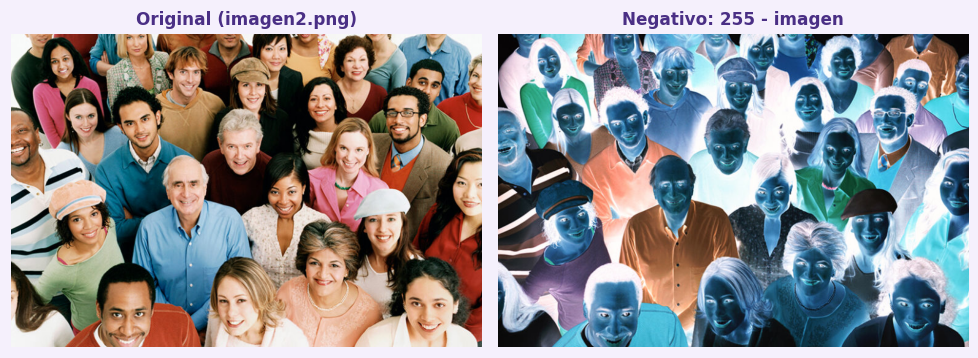

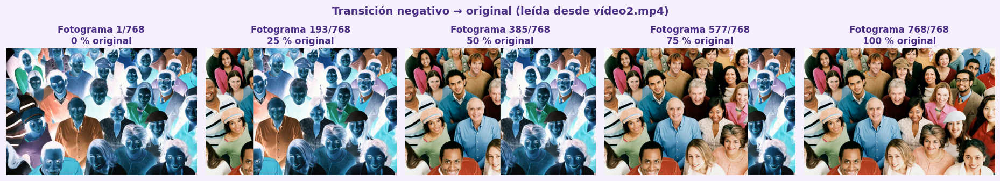

PSNR último fotograma vs original: 34.3 dB


In [3]:
mostrar([imagen, negativo], ['Original (imagen2.png)', 'Negativo: 255 - imagen'], figsize=(9, 3.6))

indices = [0, ancho // 4, ancho // 2, 3 * ancho // 4, ancho - 1]
frames = fotogramas_de_video(NOMBRE_VIDEO_1, indices)
titulos = [f'Fotograma {i + 1}/{ancho}\n{100 * (i + 1) / ancho:.0f} % original' for i in indices]
mostrar(frames, titulos, figsize=(17, 3.4), suptitulo='Transición negativo → original (leída desde vídeo2.mp4)')

print(f'PSNR último fotograma vs original: {cv.PSNR(frames[-1], imagen):.1f} dB')


<div style="background:#E8DEF8;border-left:6px solid #7B54C7;padding:10px 16px;border-radius:8px;margin:6px 0"><span style="color:#4A2F85;font-size:1.25em;font-weight:bold">Ejercicio 2 · Rango dinámico con trackbars</span><span style="float:right;color:#7A6A99">1.0 puntos</span></div>


**Qué se pide.** Una aplicación con trackbars para aplicar las transformaciones logarítmica y exponencial del rango dinámico, eligiendo la intensidad de la compresión o la expansión, con dos imágenes en las que se vea bien el efecto de ambas.

**Transformaciones.** Llamamos $r$ a la intensidad de entrada y $s$ a la de salida:

$$s = c\,\log\!\big[1 + (e^{\sigma}-1)\,r\big] \qquad s = c\,\big[(1+\alpha)^{r} - 1\big] \qquad c = \frac{L-1}{\log(1 + r_{\max})}$$

- $\sigma$ controla la compresión logarítmica y $\alpha$ la expansión exponencial. $L = 256$ y $r_{\max}$ es la intensidad máxima de la imagen.
- Como son operadores puntuales, calculamos cada transformación una sola vez para los 256 valores posibles (tabla `cv.LUT`) y la aplicamos a toda la imagen. Esa misma tabla es la curva que dibujamos en la interfaz.

**Imágenes elegidas.** `imagen3.png`, muy oscura (la logarítmica la aclara mucho), e `imagen7_2.png`, clara (la exponencial separa las zonas brillantes y oscurece el resto). Aplicamos siempre las dos transformaciones a la imagen elegida, así también se ve el efecto contrario.

**Controles.**

| Control | Rango | Efecto |
|---|---|---|
| Botón `Cambiar imagen` (o tecla `I`) | | cambia entre las dos imágenes |
| `Sigma x100` | 1 – 100 | $\sigma$ de 0.01 a 1.00 (inicio 0.50) |
| `Alfa x10000` | 0 – 100 | $\alpha$ de 0 a 0.0100 (inicio 0.0070) |

La ventana se puede redimensionar o maximizar y el contenido se escala para verse completo. Al abrirla ya se ajusta al tamaño de la pantalla.


In [ ]:
L = 256                                       
IMAGENES_EJ2 = ['imagen3.png', 'imagen7_2.png'] 
SIGMA_INI, ALFA_INI = 0.50, 0.007             

def factor_escala(r_max):
    """c = (L - 1) / log(1 + r_max)"""
    return (L - 1) / np.log(1 + max(int(r_max), 1))

def lut_logaritmica(sigma, r_max):
    """Compresión logarítmica: s = c * log[1 + (e^sigma - 1) * r]"""
    r = np.arange(L, dtype=np.float64)
    s = factor_escala(r_max) * np.log1p(np.expm1(sigma) * r)
    return np.clip(np.rint(s), 0, L - 1).astype(np.uint8)

def lut_exponencial(alfa, r_max):
    """Expansión exponencial: s = c * [(1 + alfa)^r - 1]"""
    r = np.arange(L, dtype=np.float64)
    s = factor_escala(r_max) * (np.power(1.0 + alfa, r) - 1.0)
    return np.clip(np.rint(s), 0, L - 1).astype(np.uint8)

ANCHO_PANEL, ALTO_TARJETA, MARGEN = 340, 528, 24
ANCHO_LIENZO, ALTO_LIENZO = 3 * ANCHO_PANEL + 4 * MARGEN, 650
Y_TARJETA = 84
CAJA_IMG = (316, 300)
ALTO_CURVA = 120

def _x_tarjeta(i):
    return MARGEN + i * (ANCHO_PANEL + MARGEN)

@functools.lru_cache(maxsize=1)
def _fondo_estatico():
    """Cabecera, tarjetas y textos fijos (se construye una sola vez)."""
    lienzo = np.full((ALTO_LIENZO, ANCHO_LIENZO, 3), bgr(LILA['fondo']), np.uint8)
    lienzo[:64] = degradado_horizontal(ANCHO_LIENZO, 64, LILA['oscuro'], LILA['medio'])
    # sombras suaves de las tarjetas
    sombra = np.zeros_like(lienzo)
    for i in range(3):
        x = _x_tarjeta(i)
        rect_redondeado(sombra, (x + 2, Y_TARJETA + 6), (x + ANCHO_PANEL + 2, Y_TARJETA + ALTO_TARJETA + 6), '#FFFFFF', 18)
    sombra = cv.GaussianBlur(sombra, (0, 0), 7)
    mascara = (sombra[..., :1] / 255.0)
    lienzo = (lienzo * (1 - 0.22 * mascara) + np.array(bgr(LILA['medio'])) * 0.22 * mascara).astype(np.uint8)
    for i in range(3):
        x = _x_tarjeta(i)
        rect_redondeado(lienzo, (x, Y_TARJETA), (x + ANCHO_PANEL, Y_TARJETA + ALTO_TARJETA), LILA['tarjeta'], 18)
    titulos = [('Original', 'imagen de entrada'),
               ('Compresión logarítmica', 's = c · log[1 + (e^σ − 1) · r]'),
               ('Expansión exponencial', 's = c · [(1 + α)^r − 1]')]
    textos = [('Transformaciones del rango dinámico', (MARGEN, 24), 24, '#FFFFFF', True, 'l'),
              ('Compresión logarítmica y expansión exponencial · Práctica 3 · PIAV', (MARGEN, 48), 12, LILA['claro'], False, 'l'),
              ('ESC / Q: salir   ·   S: guardar captura   ·   I o clic en el botón: cambiar imagen   ·   barras inferiores: σ (×100) y α (×10000)',
               (ANCHO_LIENZO // 2, 632), 12, LILA['gris'], False, 'm')]
    for i, (t, sub) in enumerate(titulos):
        cx = _x_tarjeta(i) + ANCHO_PANEL // 2
        textos.append((t, (cx, Y_TARJETA + 24), 16, LILA['oscuro'], True, 'm'))
        textos.append((sub, (cx, Y_TARJETA + 46), 12, LILA['gris'], False, 'm'))
    escribir_textos(lienzo, textos)
    return lienzo

def _preparar(nombre):
    original = leer_imagen(nombre, cv.IMREAD_UNCHANGED)
    if original.ndim == 3 and original.shape[2] == 4:
        original = original[..., :3]
    if original.ndim == 2:
        original = cv.cvtColor(original, cv.COLOR_GRAY2BGR)
    gris = cv.cvtColor(original, cv.COLOR_BGR2GRAY)
    hist = cv.calcHist([gris], [0], None, [L], [0, L]).ravel()
    ancho_caja, alto_caja = CAJA_IMG
    esc = min(ancho_caja / original.shape[1], alto_caja / original.shape[0])
    tam = (max(1, round(original.shape[1] * esc)), max(1, round(original.shape[0] * esc)))
    mini = cv.resize(original, tam, interpolation=cv.INTER_AREA if esc < 1 else cv.INTER_LINEAR)
    return {'nombre': nombre, 'r_max': int(original.max()), 'hist': np.sqrt(hist / hist.max()),
            'mini': mini, 'media': float(original.mean())}

DATOS_EJ2 = [_preparar(n) for n in IMAGENES_EJ2]

def _pegar_imagen(lienzo, x_tarjeta, mini):
    x0, y0 = x_tarjeta + 12, Y_TARJETA + 62
    rect_redondeado(lienzo, (x0, y0), (x0 + CAJA_IMG[0], y0 + CAJA_IMG[1]), LILA['claro'], 10)
    h, w = mini.shape[:2]
    ox, oy = x0 + (CAJA_IMG[0] - w) // 2, y0 + (CAJA_IMG[1] - h) // 2
    lienzo[oy:oy + h, ox:ox + w] = mini

def _dibujar_curva(lienzo, x_tarjeta, hist, lut, textos):
    """Caja con el histograma de entrada y, encima, la curva de transferencia."""
    x0, y0, w, h = x_tarjeta + 12, Y_TARJETA + 374, 316, ALTO_CURVA
    rect_redondeado(lienzo, (x0, y0), (x0 + w, y0 + h), LILA['fondo'], 10)
    ax0, ax1, ay0, ay1 = x0 + 14, x0 + w - 14, y0 + 10, y0 + h - 22

    def px(r): return ax0 + r / 255.0 * (ax1 - ax0)
    def py(s): return ay1 - s / 255.0 * (ay1 - ay0)

    for v in (0, 64, 128, 192, 255):                      
        cv.line(lienzo, (round(px(v)), ay0), (round(px(v)), ay1), bgr(LILA['claro']), 1, cv.LINE_AA)
        cv.line(lienzo, (ax0, round(py(v))), (ax1, round(py(v))), bgr(LILA['claro']), 1, cv.LINE_AA)
    # histograma de la imagen de entrada (sobre el eje r)
    silueta = [(round(px(0)), ay1)] + [(round(px(i)), round(ay1 - hist[i] * (ay1 - ay0) * 0.95)) for i in range(L)] + [(round(px(255)), ay1)]
    capa = lienzo.copy()
    cv.fillPoly(capa, [np.array(silueta, np.int32)], bgr(LILA['suave']), cv.LINE_AA)
    cv.addWeighted(capa, 0.75, lienzo, 0.25, 0, lienzo)
    if lut is not None:
        for t in np.linspace(0, 1, 28):                       
            if int(t * 27) % 2 == 0:
                a, b = t * 255, min(255, (t + 1 / 27) * 255)
                cv.line(lienzo, (round(px(a)), round(py(a))), (round(px(b)), round(py(b))), bgr(LILA['medio']), 1, cv.LINE_AA)
        pts = np.array([(px(i), py(int(lut[i]))) for i in range(L)], np.float32)
        cv.polylines(lienzo, [np.round(pts).astype(np.int32)], False, bgr(LILA['primario']), 2, cv.LINE_AA)
        textos.append(('s', (ax0 + 6, ay0 + 6), 11, LILA['oscuro'], True, 'l'))
    cv.rectangle(lienzo, (ax0, ay0), (ax1, ay1), bgr(LILA['suave']), 1, cv.LINE_AA)
    textos += [('0', (ax0, ay1 + 11), 11, LILA['gris'], False, 'm'),
               ('255', (ax1, ay1 + 11), 11, LILA['gris'], False, 'm'),
               ('r (intensidad de entrada)', ((ax0 + ax1) // 2, ay1 + 11), 11, LILA['gris'], False, 'm')]

TEXTO_BOTON = 'Cambiar imagen'
_ANCHO_BOTON = int(medir_texto(TEXTO_BOTON, 14, True)) + 36
BOTON = (ANCHO_LIENZO - MARGEN - _ANCHO_BOTON, 17, ANCHO_LIENZO - MARGEN, 47)   # (x1, y1, x2, y2)

def renderizar(idx, sigma, alfa, hover=False):
    """Devuelve el lienzo BGR completo para la imagen idx y los parámetros dados.
    `hover` indica si el ratón está encima del botón (se dibuja más oscuro)."""
    d = DATOS_EJ2[idx]
    lienzo = _fondo_estatico().copy()
    lut_log, lut_exp = lut_logaritmica(sigma, d['r_max']), lut_exponencial(alfa, d['r_max'])
    imagenes = [d['mini'], cv.LUT(d['mini'], lut_log), cv.LUT(d['mini'], lut_exp)]
    luts = [None, lut_log, lut_exp]
    c = factor_escala(d['r_max'])
    infos = [f"r_max = {d['r_max']}   ·   media = {d['media']:.1f}",
             f"σ = {sigma:.2f}   ·   c = {c:.1f}   ·   media = {imagenes[1].mean():.1f}",
             f"α = {alfa:.4f}   ·   c = {c:.1f}   ·   media = {imagenes[2].mean():.1f}"]
    textos = []
    for i in range(3):
        x = _x_tarjeta(i)
        _pegar_imagen(lienzo, x, imagenes[i])
        _dibujar_curva(lienzo, x, d['hist'], luts[i], textos)
        textos.append((infos[i], (x + ANCHO_PANEL // 2, Y_TARJETA + 510), 12, LILA['tinta'], False, 'm'))
    nombre = d['nombre']
    bx1, by1, bx2, by2 = BOTON
    rect_redondeado(lienzo, (bx1, by1), (bx2, by2), LILA['suave'] if hover else '#FFFFFF', 15)
    textos.append((TEXTO_BOTON, ((bx1 + bx2) // 2, 32), 14, LILA['oscuro'], True, 'm'))
    ancho_pildora = int(medir_texto(nombre, 14, True)) + 28       # nombre de la imagen actual, a la izquierda del botón
    xp = bx1 - 12
    rect_redondeado(lienzo, (xp - ancho_pildora, 17), (xp, 47), LILA['claro'], 15)
    textos.append((nombre, (xp - ancho_pildora // 2, 32), 14, LILA['oscuro'], True, 'm'))
    escribir_textos(lienzo, textos)
    return lienzo

def _tam_pantalla():
    """Ancho y alto de la pantalla en píxeles (None si no se puede averiguar)."""
    try:
        import ctypes
        usuario = ctypes.windll.user32                    # solo existe en Windows
        return usuario.GetSystemMetrics(0), usuario.GetSystemMetrics(1)
    except Exception:
        pass
    try:                                                  # macOS / Linux: se pregunta a tkinter en otro proceso
        import subprocess, sys
        orden = 'import tkinter as tk; r = tk.Tk(); print(r.winfo_screenwidth(), r.winfo_screenheight())'
        salida = subprocess.run([sys.executable, '-c', orden], capture_output=True, text=True, timeout=10).stdout.split()
        return int(salida[0]), int(salida[1])
    except Exception:
        return None

def _tam_ventana_inicial():
    """Tamaño inicial de la ventana: el del lienzo, reducido si hace falta para que quepa en la pantalla
    (se dejan unos píxeles para la barra de título, las barras de control y la barra de tareas)."""
    pantalla = _tam_pantalla()
    if pantalla is None:
        escala = 0.85
    else:
        escala = min(1.0, (pantalla[0] - 40) / ANCHO_LIENZO, (pantalla[1] - 200) / ALTO_LIENZO)
    escala = max(escala, 0.4)
    return round(ANCHO_LIENZO * escala), round(ALTO_LIENZO * escala)

def lanzar_app_rango_dinamico():
    ventana = 'Rango dinamico'
    # WINDOW_NORMAL: ventana redimensionable (también se puede maximizar). El lienzo se escala al tamaño de la
    # ventana, así que siempre se ve entero.
    cv.namedWindow(ventana, cv.WINDOW_NORMAL | cv.WINDOW_KEEPRATIO)
    cv.resizeWindow(ventana, *_tam_ventana_inicial())
    nada = lambda v: None
    cv.createTrackbar('Sigma x100', ventana, round(SIGMA_INI * 100), 100, nada)
    cv.createTrackbar('Alfa x10000', ventana, round(ALFA_INI * 10000), 100, nada)

    estado = {'idx': 0, 'hover': False}

    def raton(evento, x, y, flags, param):
        # (x, y) llegan ya en coordenadas del lienzo, aunque la ventana esté escalada
        x1, y1, x2, y2 = BOTON
        estado['hover'] = x1 <= x <= x2 and y1 <= y <= y2
        if evento == cv.EVENT_LBUTTONDOWN and estado['hover']:
            estado['idx'] = (estado['idx'] + 1) % len(DATOS_EJ2)

    cv.setMouseCallback(ventana, raton)

    anterior, lienzo = None, None
    while True:
        idx = estado['idx']
        sigma = max(cv.getTrackbarPos('Sigma x100', ventana), 1) / 100.0 
        alfa = cv.getTrackbarPos('Alfa x10000', ventana) / 10000.0       
        if (idx, sigma, alfa, estado['hover']) != anterior:
            lienzo = renderizar(idx, sigma, alfa, estado['hover'])
            cv.imshow(ventana, lienzo)
            anterior = (idx, sigma, alfa, estado['hover'])
        tecla = cv.waitKey(30) & 0xFF
        if tecla in (27, ord('q'), ord('Q')):
            break
        if tecla in (ord('i'), ord('I')):
            estado['idx'] = (estado['idx'] + 1) % len(DATOS_EJ2)
        if tecla in (ord('s'), ord('S')):
            guardar_imagen('captura_rango_dinamico.png', lienzo)
            print('Captura guardada en captura_rango_dinamico.png')
        if cv.getWindowProperty(ventana, cv.WND_PROP_VISIBLE) < 1:      
            break
    cv.destroyAllWindows()
    cv.waitKey(1)

print('Aplicación lista. Ejecuta la siguiente celda para abrirla.')


Aplicación lista. Ejecuta la siguiente celda para abrirla.


**Vista previa de la interfaz**:


In [ ]:
for idx in range(len(DATOS_EJ2)):
    fig = plt.figure(figsize=(12.5, 7.3))
    plt.imshow(a_rgb(renderizar(idx, SIGMA_INI, ALFA_INI)))
    plt.axis('off')
    plt.tight_layout(pad=0.2)
    plt.show()


**Abrir la aplicación**:


In [ ]:
lanzar_app_rango_dinamico()


<div style="background:#E8DEF8;border-left:6px solid #7B54C7;padding:10px 16px;border-radius:8px;margin:6px 0"><span style="color:#4A2F85;font-size:1.25em;font-weight:bold">Ejercicio 3 · Mezcla no lineal de dos imágenes</span><span style="float:right;color:#7A6A99">1.0 puntos</span></div>


**Qué se pide.** Mezclar `imagen7_1.jpg` e `imagen7_2.png` con

$$I_3 = \frac{1+\cos\!\left(\frac{\alpha}{180}\pi\right)}{2}\, I_1 + \frac{1-\cos\!\left(\frac{\alpha}{180}\pi\right)}{2}\, I_2$$

y crear un vídeo de 360 fotogramas subiendo el ángulo 1° por iteración, guardado como `video7.mp4`.

**Cómo lo hemos hecho.**

- Los dos pesos suman siempre 1, así que es una interpolación entre las dos imágenes, pero con un perfil de coseno: la transición empieza y acaba suave en lugar de ir a velocidad constante.
- El ángulo va de 0° a 359°. El primer fotograma es solo `imagen7_1` y el de 180° solo `imagen7_2`. El siguiente al 359° volvería a ser el primero, por lo que el vídeo encaja si se reproduce en bucle.
- Calculamos cada fotograma con `cv.addWeighted`, que ya satura y redondea a 8 bits. A 30 fps dura 12 s.


In [7]:
NOMBRE_VIDEO_3 = 'video7.mp4'
FPS_3 = 30
N_FRAMES_3 = 360                             

imagen_1 = leer_imagen('imagen7_1.jpg')
imagen_2 = leer_imagen('imagen7_2.png')
if imagen_1.shape != imagen_2.shape:       
    imagen_2 = cv.resize(imagen_2, (imagen_1.shape[1], imagen_1.shape[0]), interpolation=cv.INTER_AREA)
alto3, ancho3 = imagen_1.shape[:2]

def pesos(angulo_grados):
    """I3 = (1 + cos(a/180·π))/2 · I1 + (1 − cos(a/180·π))/2 · I2"""
    c = np.cos(angulo_grados / 180.0 * np.pi)
    return (1 + c) / 2, (1 - c) / 2

with EscritorVideo(NOMBRE_VIDEO_3, FPS_3, ancho3, alto3) as video:
    for angulo in range(N_FRAMES_3):          # 0°, 1°, ..., 359°
        w1, w2 = pesos(angulo)
        video.escribir(cv.addWeighted(imagen_1, w1, imagen_2, w2, 0))

n_frames = resumen_video(NOMBRE_VIDEO_3)
assert n_frames == N_FRAMES_3


'video7.mp4' -> 360 fotogramas | 500x400 | 30 fps | 12.0 s | 1,351 KB


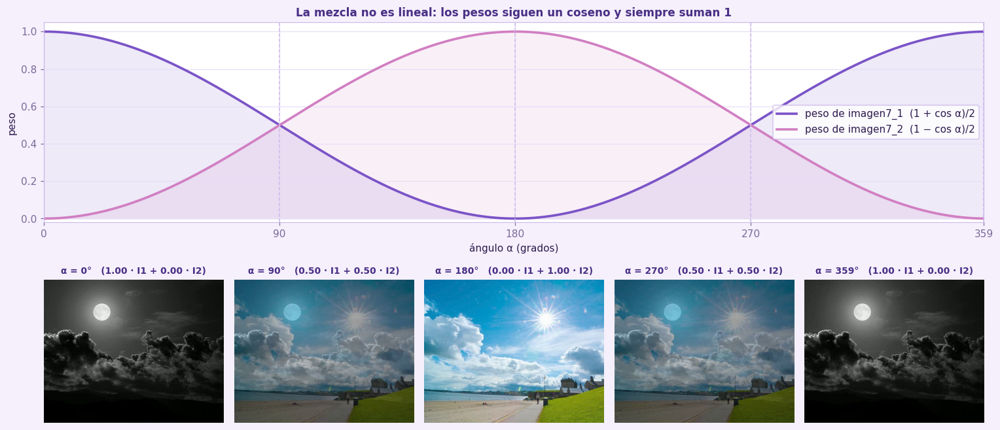

In [ ]:
angulos = np.arange(N_FRAMES_3)
w1, w2 = pesos(angulos)
muestras = [0, 90, 180, 270, 359]
frames = fotogramas_de_video(NOMBRE_VIDEO_3, muestras)

fig = plt.figure(figsize=(14, 6.2))
gs = fig.add_gridspec(2, 5, height_ratios=[1.25, 1])
ax = fig.add_subplot(gs[0, :])
ax.plot(angulos, w1, lw=2.4, label='peso de imagen7_1  (1 + cos α)/2', color=LILA['primario'])
ax.plot(angulos, w2, lw=2.4, label='peso de imagen7_2  (1 − cos α)/2', color='#D17FC2')
ax.fill_between(angulos, w1, alpha=0.12, color=LILA['primario'])
ax.fill_between(angulos, w2, alpha=0.12, color='#D17FC2')
for a in muestras:
    ax.axvline(a, color=LILA['suave'], lw=1, ls='--')
ax.set_xlim(0, 359); ax.set_ylim(-0.02, 1.05); ax.set_xticks([0, 90, 180, 270, 359])
ax.set_xlabel('ángulo α (grados)'); ax.set_ylabel('peso')
ax.set_title('La mezcla no es lineal: los pesos siguen un coseno y siempre suman 1')
ax.grid(True); ax.legend(loc='center right')
for i, (a, fr) in enumerate(zip(muestras, frames)):
    axi = fig.add_subplot(gs[1, i])
    axi.imshow(a_rgb(fr)); axi.axis('off')
    axi.set_title(f'α = {a}°   ({pesos(a)[0]:.2f} · I1 + {pesos(a)[1]:.2f} · I2)', fontsize=9)
fig.tight_layout(h_pad=2.0)
plt.show()


<div style="background:#E8DEF8;border-left:6px solid #7B54C7;padding:10px 16px;border-radius:8px;margin:6px 0"><span style="color:#4A2F85;font-size:1.25em;font-weight:bold">Ejercicio 4 · Ecualizado del histograma</span><span style="float:right;color:#7A6A99">0.5 puntos</span></div>


**Qué se pide.** Obtener el ecualizado del histograma de `imagen3.png`.

**Cómo lo hemos hecho.** `imagen3.png` es una imagen en grises muy oscura (todos sus valores están entre 13 y 83), por lo que el ecualizado reparte los niveles por todo el rango. Para el resto del trabajo usamos el resultado de `cv.equalizeHist`. Además, programamos a mano los pasos de la teoría (histograma, histograma acumulado, normalización y sustitución de valores) para comprobar que dan lo mismo. En la normalización restamos el valor mínimo del acumulado, de modo que el nivel más oscuro pase a 0; sin ese término se obtiene el resultado de la fórmula básica de la diapositiva, que no estira hasta el negro.

Guardamos el resultado como `imagen3_ecualizada.png`.


In [9]:
imagen3 = leer_imagen('imagen3.png', cv.IMREAD_GRAYSCALE)

imagen3_eq = cv.equalizeHist(imagen3)
guardar_imagen('imagen3_ecualizada.png', imagen3_eq)

def ecualizar_manual(gris):
    h = np.bincount(gris.ravel(), minlength=256)         
    H = np.cumsum(h)                                     
    H_min = H[H > 0][0]                                  
    H_norm = 255.0 * (H - H_min) / (gris.size - H_min)   
    return np.rint(H_norm).astype(np.uint8)[gris]        

imagen3_eq_manual = ecualizar_manual(imagen3)
dif = np.abs(imagen3_eq.astype(int) - imagen3_eq_manual.astype(int))
print(f'Diferencia máxima entre cv.equalizeHist y la versión manual: {dif.max()} niveles (media {dif.mean():.2f})')
print(f'Rango original:   [{imagen3.min()}, {imagen3.max()}]   media {imagen3.mean():.1f}   desv. típica {imagen3.std():.1f}')
print(f'Rango ecualizado: [{imagen3_eq.min()}, {imagen3_eq.max()}]   media {imagen3_eq.mean():.1f}   desv. típica {imagen3_eq.std():.1f}')


Diferencia máxima entre cv.equalizeHist y la versión manual: 0 niveles (media 0.00)
Rango original:   [13, 83]   media 38.7   desv. típica 17.3
Rango ecualizado: [0, 255]   media 121.5   desv. típica 77.6


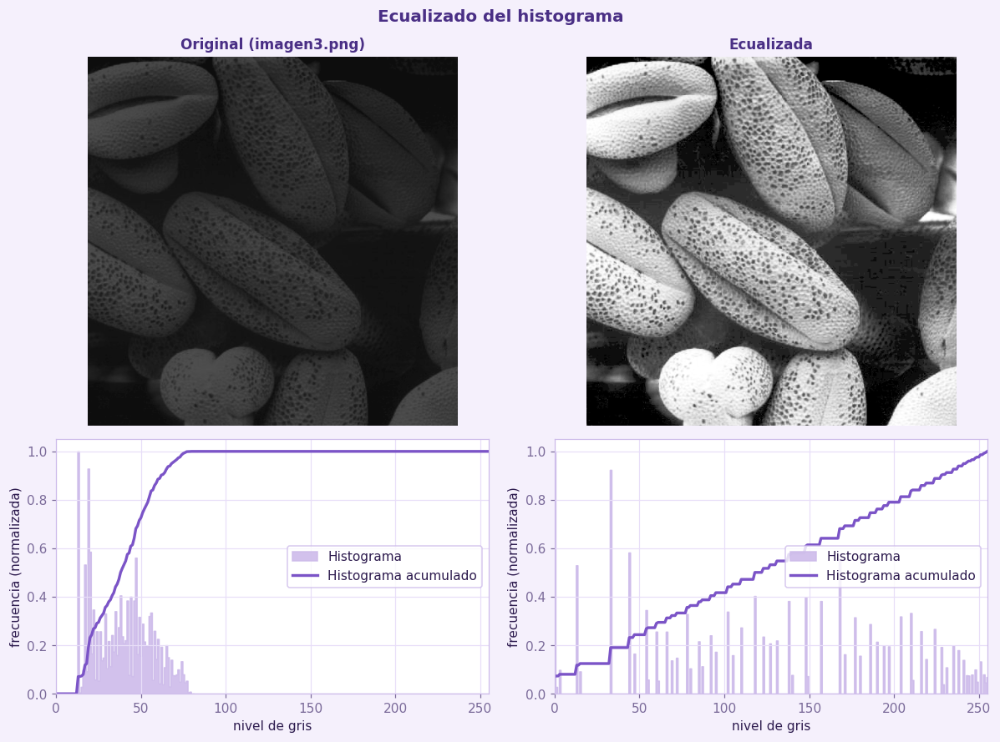

In [ ]:
def histograma(gris):
    h = cv.calcHist([gris], [0], None, [256], [0, 256]).ravel()
    return h / h.max(), np.cumsum(h) / h.sum()

fig, ejes = plt.subplots(2, 2, figsize=(11, 8.2), gridspec_kw={'height_ratios': [1.45, 1]})
for col, (im, titulo) in enumerate([(imagen3, 'Original (imagen3.png)'), (imagen3_eq, 'Ecualizada')]):
    ejes[0, col].imshow(im, cmap='gray', vmin=0, vmax=255)
    ejes[0, col].set_title(titulo); ejes[0, col].axis('off')
    h, acum = histograma(im)
    ax = ejes[1, col]
    ax.fill_between(np.arange(256), h, step='mid', color=LILA['suave'], alpha=0.9, label='Histograma')
    ax.plot(acum, color=LILA['primario'], lw=2.2, label='Histograma acumulado')
    ax.set_xlim(0, 255); ax.set_ylim(0, 1.05); ax.grid(True)
    ax.set_xlabel('nivel de gris'); ax.set_ylabel('frecuencia (normalizada)')
    ax.legend(loc='center right')
fig.suptitle('Ecualizado del histograma', fontsize=13, fontweight='bold', color=LILA['oscuro'])
fig.tight_layout()
plt.show()


<div style="background:#E8DEF8;border-left:6px solid #7B54C7;padding:10px 16px;border-radius:8px;margin:6px 0"><span style="color:#4A2F85;font-size:1.25em;font-weight:bold">Ejercicio 5 · Umbral de Otsu y vídeo de umbralizado</span><span style="float:right;color:#7A6A99">1.5 puntos</span></div>


**Qué se pide.** Calcular el umbral óptimo de Otsu (`cv.THRESH_OTSU`) de una imagen en grises y generar `video_otsu.mp4` con 256 iteraciones de umbralizado manual (umbral de 0 a 255), con el valor actual superpuesto. Al llegar al fotograma del umbral de Otsu, ese fotograma se duplica durante 2 segundos con el texto "Óptimo de Otsu".

**Cómo lo hemos hecho.**

- Imagen: `imagen4.jpg` leída en escala de grises (810 × 540).
- Cada fotograma es `cv.threshold(imagen, T, 255, cv.THRESH_BINARY)` con `T` de 0 a 255. En la esquina escribimos `Umbral = T` y abajo dibujamos un histograma con el umbral actual y la posición del de Otsu.
- Al llegar a `T = T_otsu` escribimos ese fotograma y, a continuación, 60 copias (2 s a 30 fps) con marco y etiqueta "Óptimo de Otsu". El vídeo tiene por tanto 256 + 60 = 316 fotogramas.
- `cv.putText` no dibuja la "Ó", así que dibujamos el texto con Pillow (fuente DejaVu, que ya trae Matplotlib).
- Comprobaciones: el fotograma con `T = T_otsu` coincide con la salida de `cv.THRESH_OTSU`, y si calculamos a mano la varianza intragrupal para cada `T`, el mínimo cae en el mismo valor.


In [11]:
NOMBRE_VIDEO_5 = 'video_otsu.mp4'
FPS_5 = 30
SEGUNDOS_PAUSA = 2

gris5 = leer_imagen('imagen4.jpg', cv.IMREAD_GRAYSCALE)    
alto5, ancho5 = gris5.shape

umbral_otsu, binaria_otsu = cv.threshold(gris5, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
umbral_otsu = int(umbral_otsu)
print(f'Umbral óptimo de Otsu: {umbral_otsu}')

hist5 = cv.calcHist([gris5], [0], None, [256], [0, 256]).ravel()
hist5_norm = np.sqrt(hist5 / hist5.max())

def fotograma_otsu(umbral, etiqueta_otsu=False):
    """Binarizado manual con el umbral dado + valor actual superpuesto."""
    _, binaria = cv.threshold(gris5, umbral, 255, cv.THRESH_BINARY)
    frame = cv.cvtColor(binaria, cv.COLOR_GRAY2BGR)
    textos = []

    px0, py0, pw, ph = 20, alto5 - 150, 330, 130
    rect_redondeado(frame, (px0 - 2, py0 - 2), (px0 + pw + 2, py0 + ph + 2), LILA['medio'], 14)
    rect_redondeado(frame, (px0, py0), (px0 + pw, py0 + ph), LILA['fondo'], 12, alfa=0.93)
    ax0, ax1, ay0, ay1 = px0 + 14, px0 + pw - 14, py0 + 34, py0 + ph - 22
    x = lambda v: ax0 + v / 255.0 * (ax1 - ax0)
    for i in range(256):
        alt = int(hist5_norm[i] * (ay1 - ay0))
        cv.line(frame, (round(x(i)), ay1), (round(x(i)), ay1 - alt), bgr(LILA['suave']), 1)
    cv.line(frame, (round(x(umbral_otsu)), ay0 - 4), (round(x(umbral_otsu)), ay1), bgr(LILA['medio']), 1, cv.LINE_AA)
    cv.line(frame, (round(x(umbral)), ay0 - 8), (round(x(umbral)), ay1), bgr(LILA['primario']), 2, cv.LINE_AA)
    cv.circle(frame, (round(x(umbral)), ay0 - 8), 4, bgr(LILA['primario']), -1, cv.LINE_AA)
    textos += [('Histograma', (px0 + 14, py0 + 16), 12, LILA['oscuro'], True, 'l'),
               ('0', (ax0, ay1 + 11), 10, LILA['gris'], False, 'm'),
               ('255', (ax1, ay1 + 11), 10, LILA['gris'], False, 'm'),
               (f'Otsu = {umbral_otsu}', (ax1, py0 + 16), 11, LILA['gris'], False, 'r')]

    cadena = f'Umbral = {umbral:3d}'
    ancho_p = int(medir_texto(cadena, 24, True)) + 36
    rect_redondeado(frame, (18, 18), (22 + ancho_p, 68), LILA['medio'], 25)
    rect_redondeado(frame, (20, 20), (20 + ancho_p, 66), LILA['claro'], 23, alfa=0.95)
    textos.append((cadena, (20 + ancho_p // 2, 43), 24, LILA['oscuro'], True, 'm'))

    if etiqueta_otsu:                                         # fotograma del umbral óptimo
        cv.rectangle(frame, (0, 0), (ancho5 - 1, alto5 - 1), bgr(LILA['primario']), 8, cv.LINE_AA)
        cadena = 'Óptimo de Otsu'
        ancho_e = int(medir_texto(cadena, 38, True)) + 56
        x0 = ancho5 // 2 - ancho_e // 2
        rect_redondeado(frame, (x0, alto5 // 2 - 36), (x0 + ancho_e, alto5 // 2 + 36), LILA['primario'], 36, alfa=0.93)
        textos.append((cadena, (ancho5 // 2, alto5 // 2), 38, '#FFFFFF', True, 'm'))
    escribir_textos(frame, textos)
    return frame

with EscritorVideo(NOMBRE_VIDEO_5, FPS_5, ancho5, alto5) as video:
    for umbral in range(256):
        video.escribir(fotograma_otsu(umbral))
        if umbral == umbral_otsu:
            pausa = fotograma_otsu(umbral, etiqueta_otsu=True)
            for _ in range(SEGUNDOS_PAUSA * FPS_5):
                video.escribir(pausa)

n_esperado = 256 + SEGUNDOS_PAUSA * FPS_5
n_frames = resumen_video(NOMBRE_VIDEO_5)
assert n_frames == n_esperado, (n_frames, n_esperado)

assert np.array_equal(cv.threshold(gris5, umbral_otsu, 255, cv.THRESH_BINARY)[1], binaria_otsu)


Umbral óptimo de Otsu: 101
'video_otsu.mp4' -> 316 fotogramas | 810x540 | 30 fps | 10.5 s | 15,407 KB


Mínimo de la varianza intragrupal: T = 101   |   cv.THRESH_OTSU: T = 101


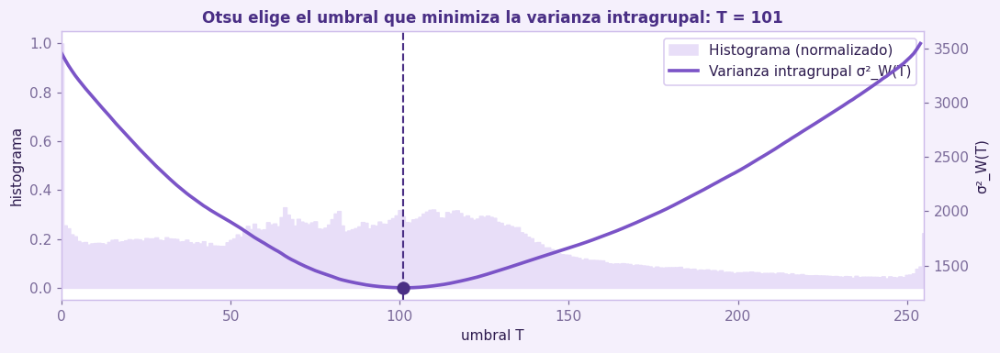

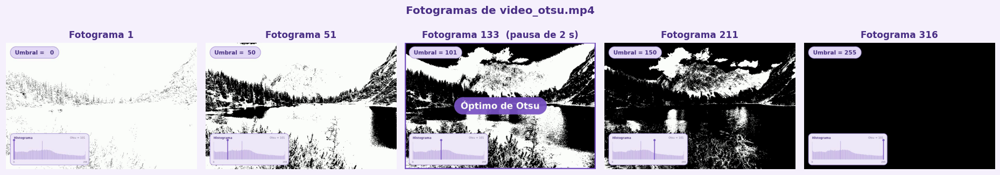

In [12]:
p = hist5 / hist5.sum()
niveles = np.arange(256)
varianza_intra = np.full(256, np.nan)
for t in range(255):
    w_b, w_f = p[:t + 1].sum(), p[t + 1:].sum()          
    if w_b == 0 or w_f == 0:
        continue
    m_b = (niveles[:t + 1] * p[:t + 1]).sum() / w_b
    m_f = (niveles[t + 1:] * p[t + 1:]).sum() / w_f
    v_b = (((niveles[:t + 1] - m_b) ** 2) * p[:t + 1]).sum() / w_b
    v_f = (((niveles[t + 1:] - m_f) ** 2) * p[t + 1:]).sum() / w_f
    varianza_intra[t] = w_b * v_b + w_f * v_f
t_min = int(np.nanargmin(varianza_intra))
print(f'Mínimo de la varianza intragrupal: T = {t_min}   |   cv.THRESH_OTSU: T = {umbral_otsu}')

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.fill_between(niveles, hist5 / hist5.max(), step='mid', color=LILA['claro'], label='Histograma (normalizado)')
ax.set_ylabel('histograma'); ax.set_xlabel('umbral T'); ax.set_xlim(0, 255)
ax2 = ax.twinx()
ax2.plot(niveles, varianza_intra, color=LILA['primario'], lw=2.4, label='Varianza intragrupal σ²_W(T)')
ax2.axvline(umbral_otsu, color=LILA['oscuro'], ls='--', lw=1.4)
ax2.scatter([umbral_otsu], [varianza_intra[umbral_otsu]], s=70, color=LILA['oscuro'], zorder=5)
ax2.set_ylabel('σ²_W(T)'); ax2.spines['right'].set_visible(True)
ax.set_title(f'Otsu elige el umbral que minimiza la varianza intragrupal: T = {umbral_otsu}')
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc='upper right')
fig.tight_layout(); plt.show()

muestras = [0, 50, umbral_otsu, 150, 255]
indices = [m if m <= umbral_otsu else m + SEGUNDOS_PAUSA * FPS_5 for m in muestras]
indices[2] = umbral_otsu + 1 + FPS_5                     
mostrar(fotogramas_de_video(NOMBRE_VIDEO_5, indices),
        [f'Fotograma {i + 1}' + ('  (pausa de 2 s)' if i == indices[2] else '') for i in indices],
        figsize=(17, 3.2), suptitulo='Fotogramas de video_otsu.mp4')


<div style="background:#E8DEF8;border-left:6px solid #7B54C7;padding:10px 16px;border-radius:8px;margin:6px 0"><span style="color:#4A2F85;font-size:1.25em;font-weight:bold">Ejercicio 6 · Filtro bilateral sobre el ecualizado</span><span style="float:right;color:#7A6A99">0.5 puntos</span></div>


**Qué se pide.** Quitar el ruido de la imagen resultado del ejercicio 4 con un filtro bilateral de diámetro `d = 10` y sigmas 11 y 11, y guardarla como `imagen3_salida.png`.

**Cómo lo hemos hecho.** La entrada es la imagen ecualizada del ejercicio 4 (el ecualizado amplifica el ruido de una imagen tan oscura). `cv.bilateralFilter(imagen, 10, 11, 11)` pondera cada vecino por su cercanía y por lo parecida que sea su intensidad, de modo que suaviza el grano sin cruzar los bordes. Con sigmas tan bajos el filtrado es suave: la diferencia máxima con la entrada es pequeña y los contornos se mantienen, como se ve en el perfil de una fila.


In [13]:
imagen3_salida = cv.bilateralFilter(imagen3_eq, d=10, sigmaColor=11, sigmaSpace=11)
guardar_imagen('imagen3_salida.png', imagen3_salida)
print(f"Guardada 'imagen3_salida.png' {imagen3_salida.shape} {imagen3_salida.dtype}")


Guardada 'imagen3_salida.png' (500, 500) uint8


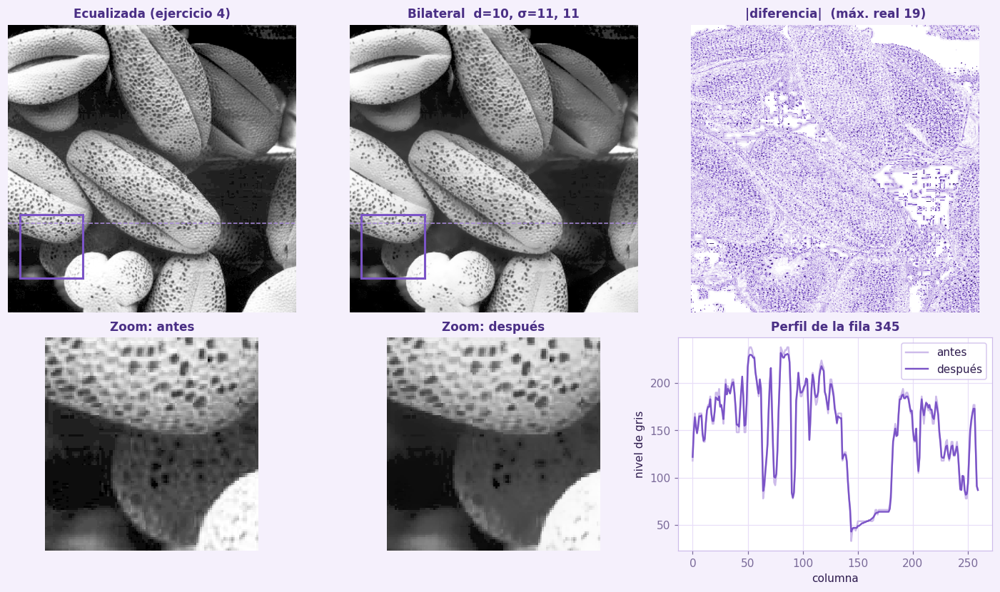

In [ ]:
diferencia = cv.absdiff(imagen3_eq, imagen3_salida)
y0, x0, lado = 330, 20, 110                        
fila = 345                                         
zoom_a = imagen3_eq[y0:y0 + lado, x0:x0 + lado]
zoom_b = imagen3_salida[y0:y0 + lado, x0:x0 + lado]
vmax_dif = max(float(np.percentile(diferencia, 99.5)), 1.0)

fig = plt.figure(figsize=(13, 7.6))
gs = fig.add_gridspec(2, 3, height_ratios=[1.35, 1])
for i, (im, t) in enumerate([(imagen3_eq, 'Ecualizada (ejercicio 4)'),
                             (imagen3_salida, 'Bilateral  d=10, σ=11, 11'),
                             (diferencia, f'|diferencia|  (máx. real {diferencia.max()})')]):
    ax = fig.add_subplot(gs[0, i])
    ax.imshow(im, cmap='gray' if i < 2 else CMAP_LILA, vmin=0, vmax=255 if i < 2 else vmax_dif)
    ax.set_title(t); ax.axis('off')
    if i < 2:
        ax.add_patch(mpl.patches.Rectangle((x0, y0), lado, lado, fill=False, ec=LILA['primario'], lw=2))
        ax.axhline(fila, color=LILA['medio'], lw=1, ls='--')
for i, (im, t) in enumerate([(zoom_a, 'Zoom: antes'), (zoom_b, 'Zoom: después')]):
    ax = fig.add_subplot(gs[1, i])
    ax.imshow(im, cmap='gray', vmin=0, vmax=255, interpolation='nearest')
    ax.set_title(t); ax.axis('off')
ax = fig.add_subplot(gs[1, 2])
ax.plot(imagen3_eq[fila, :260], color=LILA['suave'], lw=1.6, label='antes')
ax.plot(imagen3_salida[fila, :260], color=LILA['primario'], lw=1.6, label='después')
ax.set_title(f'Perfil de la fila {fila}')
ax.set_xlabel('columna'); ax.set_ylabel('nivel de gris'); ax.grid(True); ax.legend()
fig.tight_layout()
plt.show()


<div style="background:#E8DEF8;border-left:6px solid #7B54C7;padding:10px 16px;border-radius:8px;margin:6px 0"><span style="color:#4A2F85;font-size:1.25em;font-weight:bold">Ejercicio 7 · Operadores de Sobel y filtro Gaussiano</span><span style="float:right;color:#7A6A99">1.0 puntos</span></div>

**Qué se pide.** Calcular la norma del gradiente de la imagen 5 con los operadores de Sobel, umbralizarla (los valores $\ge 128$ pasan a 255 y los $< 128$ a 0), aplicar un filtro Gaussiano de radio `(7,7)` con `sigma=-1` y guardar el resultado como `imagen5_salida.png`.

**Cómo lo hemos hecho.**

- El enunciado nombra la imagen como `imagen5.jpg`, pero en el zip de recursos el fichero se llama `imagen5.png`, así que usamos ese. Lo leemos en escala de grises.
- Calculamos las derivadas en X e Y con `cv.Sobel` (`ksize=3`) en coma flotante de 64 bits, para conservar los valores negativos, y la norma es $\|\nabla f\| = \sqrt{G_x^2 + G_y^2}$.
- La norma puede pasar de 255, así que la recortamos a 8 bits antes de umbralizar. Eso no cambia el resultado, porque el umbral es 128.
- `cv.threshold(..., 127, 255, cv.THRESH_BINARY)` pone a 255 los valores **mayores que 127**, es decir, los $\ge 128$ que pide el enunciado, y a 0 el resto.
- Con `sigma=-1` OpenCV elige el sigma a partir del tamaño del núcleo. Para 7×7 usa un núcleo equivalente a $\sigma \approx 1.4$.


Guardada 'imagen5_salida.png' (1057, 1600) uint8
Valores distintos tras la umbralización: [  0 255]


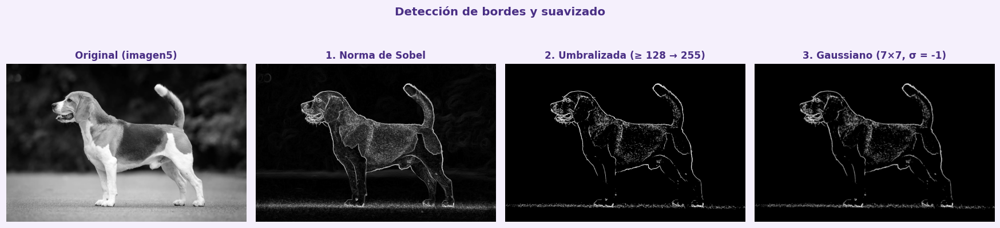

In [15]:
imagen5 = leer_imagen('imagen5.png', cv.IMREAD_GRAYSCALE)

sobel_x = cv.Sobel(imagen5, cv.CV_64F, 1, 0, ksize=3)
sobel_y = cv.Sobel(imagen5, cv.CV_64F, 0, 1, ksize=3)
norma_gradiente = np.hypot(sobel_x, sobel_y)                  

norma_8u = np.clip(norma_gradiente, 0, 255).astype(np.uint8) 

_, norma_umbralizada = cv.threshold(norma_8u, 127, 255, cv.THRESH_BINARY)

imagen5_salida = cv.GaussianBlur(norma_umbralizada, (7, 7), -1)

guardar_imagen('imagen5_salida.png', imagen5_salida)
print(f"Guardada 'imagen5_salida.png' {imagen5_salida.shape} {imagen5_salida.dtype}")
print(f'Valores distintos tras la umbralización: {np.unique(norma_umbralizada)}')

mostrar(
    [imagen5, norma_8u, norma_umbralizada, imagen5_salida],
    ['Original (imagen5)', '1. Norma de Sobel', '2. Umbralizada (≥ 128 → 255)', '3. Gaussiano (7×7, σ = -1)'],
    columnas=4, figsize=(16, 4.2),
    suptitulo='Detección de bordes y suavizado'
)


<div style="background:#E8DEF8;border-left:6px solid #7B54C7;padding:10px 16px;border-radius:8px;margin:6px 0"><span style="color:#4A2F85;font-size:1.25em;font-weight:bold">Ejercicio 8 · Filtro mediano iterativo (vídeo)</span><span style="float:right;color:#7A6A99">0.5 puntos</span></div>

**Qué se pide.** Con `imagen4.jpg`, crear un vídeo de 100 fotogramas aplicando un filtro mediano de tamaño (`ksize`) 7. En cada iteración el filtro se aplica al resultado de la iteración anterior. Se guarda como `video4.mp4`.

**Cómo lo hemos hecho.**

- Cargamos la imagen a color y hacemos un bucle de 100 iteraciones: escribimos el fotograma actual y a continuación le aplicamos `cv.medianBlur(frame, 7)`. El fotograma 1 es la imagen original, y cada uno de los siguientes es el filtrado del anterior.
- Tras muchas pasadas, el mediano va eliminando textura y deja zonas planas con bordes marcados, parecido a una pintura.


'video4.mp4' -> 100 fotogramas | 810x540 | 15 fps | 6.7 s | 560 KB


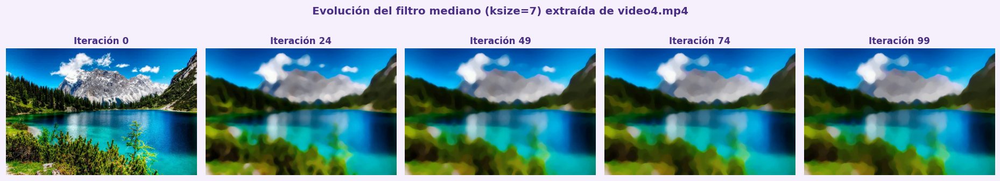

In [16]:
NOMBRE_VIDEO_8 = 'video4.mp4'
N_FRAMES_8 = 100
FPS_8 = 15  

imagen4 = leer_imagen('imagen4.jpg')
alto4, ancho4 = imagen4.shape[:2]

frame_actual = imagen4.copy()

with EscritorVideo(NOMBRE_VIDEO_8, FPS_8, ancho4, alto4) as video:
    for iteracion in range(N_FRAMES_8):
        video.escribir(frame_actual)
        frame_actual = cv.medianBlur(frame_actual, 7)

n_frames_8 = resumen_video(NOMBRE_VIDEO_8)
assert n_frames_8 == N_FRAMES_8, f"Se esperaban {N_FRAMES_8} fotogramas, se generaron {n_frames_8}."

indices_prev = [0, 24, 49, 74, 99]
frames_prev = fotogramas_de_video(NOMBRE_VIDEO_8, indices_prev)
titulos_prev = [f'Iteración {i}' for i in indices_prev]

mostrar(
    frames_prev, 
    titulos_prev, 
    figsize=(17, 3.4), 
    suptitulo='Evolución del filtro mediano (ksize=7) extraída de video4.mp4'
)

<div style="background:#E8DEF8;border-left:6px solid #7B54C7;padding:10px 16px;border-radius:8px;margin:6px 0"><span style="color:#4A2F85;font-size:1.25em;font-weight:bold">Ejercicio 9 · Eliminación de ruido y estudio comparativo</span><span style="float:right;color:#7A6A99">1.0 puntos</span></div>

**Qué se pide.** Eliminar el ruido de `imagen6.png` con los algoritmos vistos en clase, repitiendo los filtros si hace falta, hacer un estudio comparativo breve y elegir el mejor resultado.

**Cómo lo planteamos.**

1. Primero miramos **qué tipo de ruido tiene** la imagen, porque de eso depende qué filtro conviene.
2. Probamos todos los filtros de clase para quitar ruido (media, gaussiano, mediana, bilateral, non-local means) y también el mínimo y el máximo, con 1, 2 y 3 pasadas.
3. No tenemos la imagen limpia de `imagen6.png`, así que no podemos medir el error directamente. Para poder comparar con números, repetimos la prueba sobre una foto limpia (`imagen4.jpg`) a la que añadimos ruido con las mismas características y medimos PSNR y SSIM contra el original.
4. El filtro que salga mejor en esa prueba es el que aplicamos a `imagen6.png`, y lo comprobamos a ojo sobre la propia imagen.


Canal B: 14.9 % de los valores a 0   |   15.4 % a 255
Canal G: 15.1 % de los valores a 0   |   15.0 % a 255
Canal R: 14.9 % de los valores a 0   |   15.1 % a 255


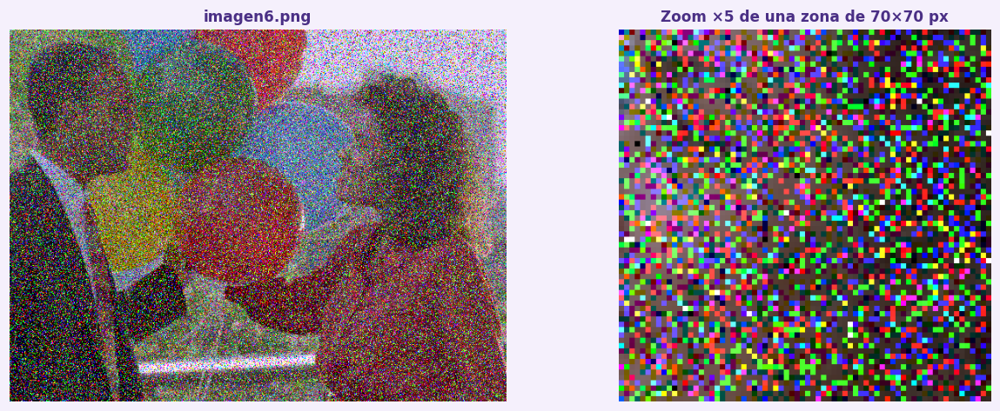

In [17]:
imagen6 = leer_imagen('imagen6.png')

for i, canal in enumerate('BGR'):
    ch = imagen6[..., i]
    print(f'Canal {canal}: {100 * (ch == 0).mean():4.1f} % de los valores a 0   |   {100 * (ch == 255).mean():4.1f} % a 255')

y0, x0, lado = 130, 440, 70
zoom = cv.resize(imagen6[y0:y0 + lado, x0:x0 + lado], None, fx=5, fy=5, interpolation=cv.INTER_NEAREST)
mostrar([imagen6, zoom], ['imagen6.png', f'Zoom ×5 de una zona de {lado}×{lado} px'], figsize=(12, 4.4))


**Tipo de ruido.** Aproximadamente el 15 % de los valores de cada canal valen 0 y otro 15 % valen 255, y el resto está intacto. Es ruido **impulsivo de tipo sal y pimienta, aplicado por canal** (por eso los puntos son de colores). Es muy denso: casi un tercio de los valores está corrompido. Por lo que vimos en clase, el filtro adecuado debería ser el mediano, y las pruebas siguientes lo comprueban.


In [18]:
def ssim(a, b):
    """SSIM medio (ventana gaussiana 11x11, sigma 1.5), promediado sobre los canales."""
    a, b = a.astype(np.float64), b.astype(np.float64)
    if a.ndim == 2:
        a, b = a[..., None], b[..., None]
    C1, C2 = (0.01 * 255) ** 2, (0.03 * 255) ** 2
    suave = lambda x: cv.GaussianBlur(x, (11, 11), 1.5)
    valores = []
    for c in range(a.shape[2]):
        x, y = a[..., c], b[..., c]
        mx, my = suave(x), suave(y)
        sxx, syy, sxy = suave(x * x) - mx ** 2, suave(y * y) - my ** 2, suave(x * y) - mx * my
        mapa = ((2 * mx * my + C1) * (2 * sxy + C2)) / ((mx ** 2 + my ** 2 + C1) * (sxx + syy + C2))
        valores.append(mapa[5:-5, 5:-5].mean())
    return float(np.mean(valores))

def ruido_sal_pimienta(imagen, p, semilla=0):
    """Pone a 0 una fracción p de los valores y a 255 otra fracción p (cada canal por separado)."""
    r = np.random.default_rng(semilla).random(imagen.shape)
    salida = imagen.copy()
    salida[r < p] = 0
    salida[r > 1 - p] = 255
    return salida

UNOS = np.ones((3, 3), np.uint8)
FILTROS = {
    'Media 5×5':             lambda x: cv.blur(x, (5, 5)),
    'Gaussiano 5×5':         lambda x: cv.GaussianBlur(x, (5, 5), 0),
    'Mediana 3×3':           lambda x: cv.medianBlur(x, 3),
    'Mediana 5×5':           lambda x: cv.medianBlur(x, 5),
    'Bilateral (d=9, σ=75)': lambda x: cv.bilateralFilter(x, 9, 75, 75),
    'Non-local means':       lambda x: cv.fastNlMeansDenoisingColored(x, None, 15, 15, 7, 21),
    'Mínimo 3×3':            lambda x: cv.erode(x, UNOS),
    'Máximo 3×3':            lambda x: cv.dilate(x, UNOS),
}
PASADAS = 3

def aplicar_pasadas(filtro, imagen, n):
    """Aplica el filtro n veces seguidas (cada pasada sobre el resultado anterior)
    y devuelve la lista de resultados tras 1, 2, ..., n pasadas."""
    resultados, actual = [], imagen
    for _ in range(n):
        actual = filtro(actual)
        resultados.append(actual)
    return resultados

limpia = cv.resize(leer_imagen('imagen4.jpg'), (imagen6.shape[1], imagen6.shape[0]), interpolation=cv.INTER_AREA)
ruidosa = ruido_sal_pimienta(limpia, 0.15)

medidas = {}      
sobre_real = {}   
for nombre, f in FILTROS.items():
    sinteticas = aplicar_pasadas(f, ruidosa, PASADAS)
    reales = aplicar_pasadas(f, imagen6, PASADAS)
    for n, (s, r) in enumerate(zip(sinteticas, reales), start=1):
        medidas[(nombre, n)] = (cv.PSNR(limpia, s), ssim(limpia, s))
        sobre_real[(nombre, n)] = r

print(f'Con ruido y sin filtrar: PSNR = {cv.PSNR(limpia, ruidosa):.2f} dB   SSIM = {ssim(limpia, ruidosa):.3f}\n')
print(f"{'Filtro':<24}" + ''.join(f'{f"{n} pasada" + ("s" if n > 1 else ""):>20}' for n in range(1, PASADAS + 1)))
print(f"{'':<24}" + ''.join(f"{'PSNR / SSIM':>20}" for _ in range(PASADAS)))
for nombre in FILTROS:
    fila = ''.join(f'{medidas[(nombre, n)][0]:>12.2f} / {medidas[(nombre, n)][1]:.3f}' for n in range(1, PASADAS + 1))
    print(f'{nombre:<24}{fila}')


Con ruido y sin filtrar: PSNR = 9.68 dB   SSIM = 0.112

Filtro                              1 pasada           2 pasadas           3 pasadas
                                 PSNR / SSIM         PSNR / SSIM         PSNR / SSIM
Media 5×5                      17.09 / 0.274       17.34 / 0.337       17.23 / 0.335
Gaussiano 5×5                  16.83 / 0.289       17.29 / 0.318       17.36 / 0.330
Mediana 3×3                    20.56 / 0.629       23.03 / 0.713       22.93 / 0.689
Mediana 5×5                    21.99 / 0.618       21.85 / 0.607       21.41 / 0.575
Bilateral (d=9, σ=75)          10.30 / 0.110       10.85 / 0.119       11.36 / 0.143
Non-local means                 9.71 / 0.113        9.72 / 0.113        9.72 / 0.113
Mínimo 3×3                      7.34 / 0.101        6.34 / 0.072        6.28 / 0.071
Máximo 3×3                      4.26 / 0.078        3.23 / 0.156        3.16 / 0.183


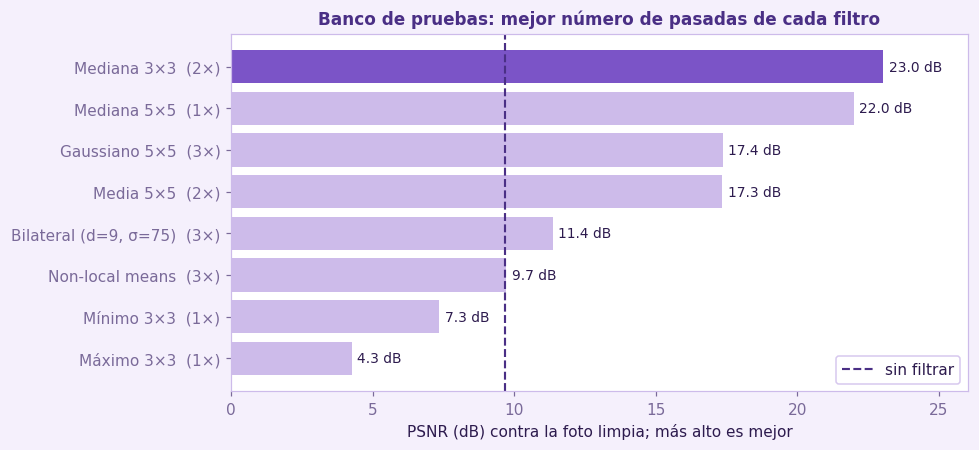

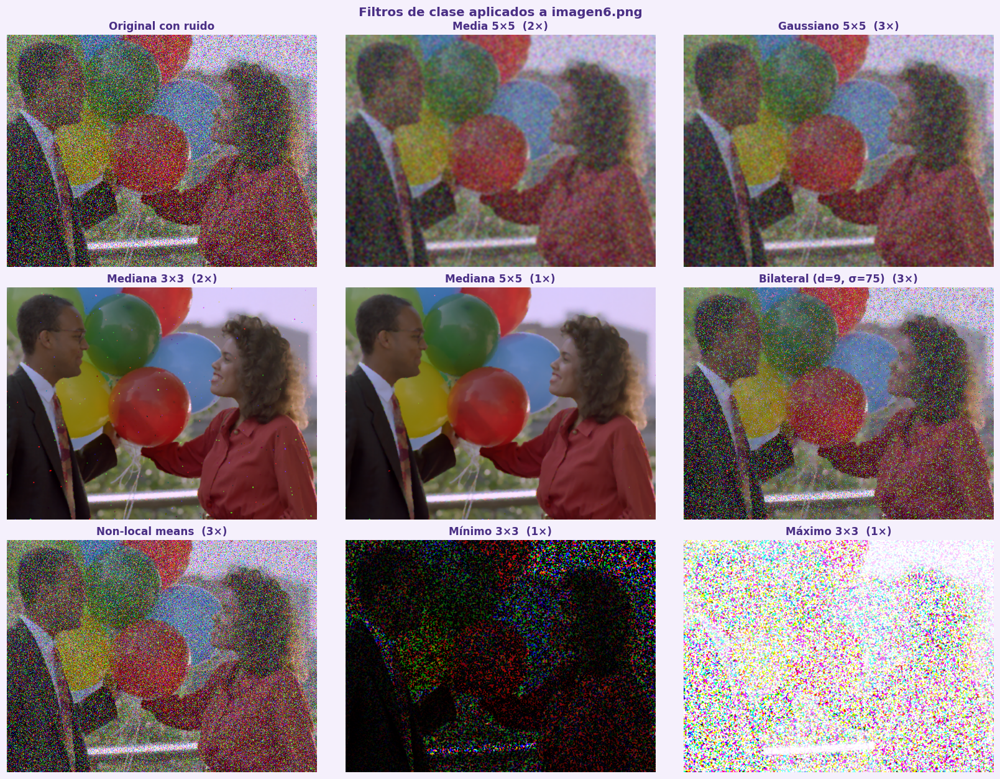

In [19]:
mejores = {nombre: max(range(1, PASADAS + 1), key=lambda n: medidas[(nombre, n)][0]) for nombre in FILTROS}

orden = sorted(FILTROS, key=lambda nombre: medidas[(nombre, mejores[nombre])][0])
fig, ax = plt.subplots(figsize=(9, 4.2))
valores = [medidas[(nombre, mejores[nombre])][0] for nombre in orden]
colores = [LILA['primario'] if nombre == orden[-1] else LILA['suave'] for nombre in orden]
barras = ax.barh([f'{nombre}  ({mejores[nombre]}×)' for nombre in orden], valores, color=colores)
ax.axvline(cv.PSNR(limpia, ruidosa), color=LILA['oscuro'], ls='--', lw=1.4, label='sin filtrar')
for b, v in zip(barras, valores):
    ax.text(v + 0.2, b.get_y() + b.get_height() / 2, f'{v:.1f} dB', va='center', fontsize=9, color=LILA['tinta'])
ax.set_xlabel('PSNR (dB) contra la foto limpia; más alto es mejor')
ax.set_title('Banco de pruebas: mejor número de pasadas de cada filtro')
ax.legend(loc='lower right'); ax.set_xlim(0, max(valores) + 3)
fig.tight_layout(); plt.show()

imagenes = [imagen6] + [sobre_real[(nombre, mejores[nombre])] for nombre in FILTROS]
titulos = ['Original con ruido'] + [f'{nombre}  ({mejores[nombre]}×)' for nombre in FILTROS]
mostrar(imagenes, titulos, columnas=3, figsize=(15, 11.6), suptitulo='Filtros de clase aplicados a imagen6.png')


Mejor resultado: Mediana 3×3, 2 pasadas  (PSNR = 23.03 dB, SSIM = 0.713).  Guardado en 'imagen6_salida.png'


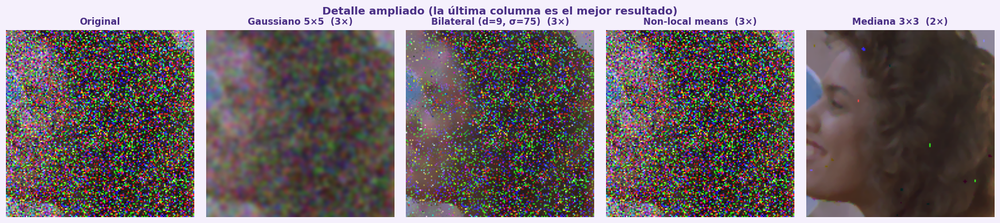

In [20]:
mejor = max(medidas, key=lambda k: medidas[k][0])          
nombre_mejor, pasadas_mejor = mejor
imagen6_salida = sobre_real[mejor]
guardar_imagen('imagen6_salida.png', imagen6_salida)
print(f"Mejor resultado: {nombre_mejor}, {pasadas_mejor} pasadas  "
      f"(PSNR = {medidas[mejor][0]:.2f} dB, SSIM = {medidas[mejor][1]:.3f}).  Guardado en 'imagen6_salida.png'")

y0, x0, lado = 90, 430, 150
claves = [('Gaussiano 5×5', mejores['Gaussiano 5×5']), ('Bilateral (d=9, σ=75)', mejores['Bilateral (d=9, σ=75)']),
          ('Non-local means', mejores['Non-local means']), mejor]
recortes = [imagen6[y0:y0 + lado, x0:x0 + lado]] + [sobre_real[k][y0:y0 + lado, x0:x0 + lado] for k in claves]
mostrar(recortes, ['Original'] + [f'{n}  ({p}×)' for n, p in claves], columnas=5, figsize=(17, 3.8),
        suptitulo='Detalle ampliado (la última columna es el mejor resultado)')


**Resultados del estudio comparativo** (PSNR sobre la foto con ruido sintético; el resto de números están en la tabla de arriba):

- **Media y gaussiano** (≈ 17 dB): reducen algo el ruido, pero a costa de emborronar. Promediar mezcla los valores 0 y 255 con los de los vecinos y deja una niebla de color, y repetir el filtro apenas mejora.
- **Bilateral y non-local means** (≈ 11 dB y ≈ 10 dB): casi no mejoran la imagen. Ambos se apoyan en que los píxeles vecinos se parezcan al central, y con un 30 % de valores corrompidos esa referencia no es fiable.
- **Mínimo y máximo**: empeoran la imagen. El mínimo elimina la sal pero extiende la pimienta (la imagen se oscurece), y el máximo hace lo contrario (se satura).
- **Mediana**: es con diferencia el mejor, como dice la teoría para ruido impulsivo. La 3×3 con una pasada deja bastantes puntos (20.6 dB). Con **dos pasadas** llega a **23.0 dB y SSIM 0.71**, el mejor resultado de todos. La 5×5 con una pasada queda en 22.0 dB y quita más detalle, y una tercera pasada de la 3×3 ya empeora ligeramente (22.9 dB).

**Resultado elegido: filtro mediano 3×3 aplicado dos veces**, que guardamos como `imagen6_salida.png`. Tiene una limitación: con un ruido tan denso quedan algunos puntos sueltos que la mediana no logra eliminar, como se ve en el detalle ampliado. Los números salen de otra foto con ruido sintético de la misma densidad, no de `imagen6.png` (de la que no tenemos la versión limpia), pero el resultado sobre la propia imagen lo confirma. En el ejercicio 10 proponemos un filtro que supera a la mediana en este tipo de ruido.


<div style="background:#E8DEF8;border-left:6px solid #7B54C7;padding:10px 16px;border-radius:8px;margin:6px 0"><span style="color:#4A2F85;font-size:1.25em;font-weight:bold">Ejercicio 10 · Una técnica de filtrado nueva y dos filtros propios</span><span style="float:right;color:#7A6A99">2.0 puntos</span></div>

**Qué se pide.** Investigar una técnica de filtrado distinta de las vistas en clase, explicarla y programar un ejemplo; después proponer dos filtros de nuestra invención (lineales o no lineales) para detectar bordes o quitar ruido.

## Parte A · Difusión anisótropa de Perona-Malik

**Idea.** Un filtro gaussiano es equivalente a dejar que la imagen se "difunda" como el calor: la intensidad se reparte entre píxeles vecinos con la misma facilidad en todas las direcciones, y por eso emborrona los bordes. Perona y Malik (1990) proponen que la difusión dependa del gradiente: **fuerte en zonas casi uniformes y débil donde hay un borde**. Así el ruido de las zonas planas se suaviza, y los bordes se conservan.

**Ecuación.** Con $I(x, y, t)$ la imagen en la iteración $t$:

$$\frac{\partial I}{\partial t} = \operatorname{div}\big( g(\|\nabla I\|)\, \nabla I \big), \qquad g(s) = e^{-(s/K)^2}$$

$g$ es la *conductancia*: vale casi 1 si el gradiente es pequeño (difunde) y casi 0 si es grande (frena). $K$ marca a partir de qué gradiente se considera borde. Si $g \equiv 1$ se obtiene la ecuación del calor, es decir, un filtro gaussiano. Los autores proponen también $g(s) = 1/(1+(s/K)^2)$.

**Versión discreta** con los 4 vecinos (N, S, E, O), con $\nabla_d I = I(\text{vecino}_d) - I(x, y)$:

$$I^{t+1}(x, y) = I^{t}(x, y) + \lambda \sum_{d \in \{N, S, E, O\}} g\big(|\nabla_d I^t|\big)\, \nabla_d I^t, \qquad 0 < \lambda \le \tfrac14$$

**Parámetros.** $K$ (umbral de borde), el número de iteraciones (cuánto suaviza) y $\lambda$ (paso, $\le 1/4$ para que sea estable).

**Cuándo sirve y cuándo no.**
- Es adecuada para ruido gaussiano, que tiene gradientes pequeños. Un píxel de sal y pimienta tiene un gradiente enorme con sus vecinos, así que la difusión lo trata como un borde y lo conserva.
- Si se itera demasiado o $K$ es grande, aparecen zonas planas "a trozos" y se pierden detalles finos.

*Referencia:* P. Perona y J. Malik, «Scale-space and edge detection using anisotropic diffusion», IEEE Transactions on Pattern Analysis and Machine Intelligence, 12(7), 1990.


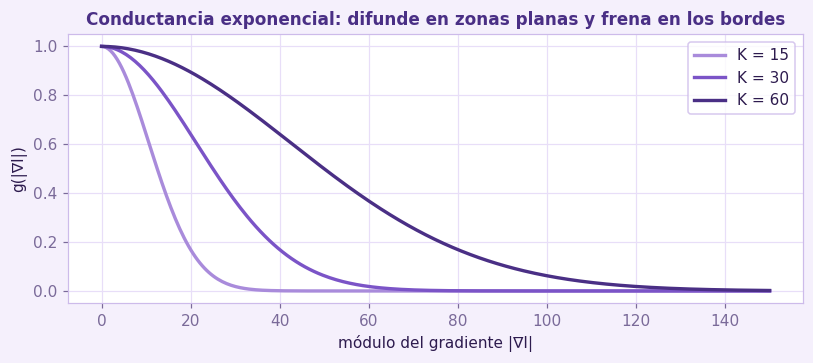

In [21]:
def conductancia(s, K, tipo='exp'):
    """g(s): ~1 para gradientes pequeños (difunde), ~0 para grandes (frena)."""
    if tipo == 'exp':
        return np.exp(-(s / K) ** 2)
    return 1.0 / (1.0 + (s / K) ** 2)

def perona_malik(imagen, iteraciones=15, K=30.0, lam=0.2, tipo='exp'):
    """Difusión anisótropa de Perona-Malik con los 4 vecinos. Vale para gris o color (cada canal por separado)."""
    u = imagen.astype(np.float32)
    relleno = ((1, 1), (1, 1)) + ((0, 0),) * (u.ndim - 2)
    for _ in range(iteraciones):
        p = np.pad(u, relleno, mode='edge')
        dN, dS = p[:-2, 1:-1] - u, p[2:, 1:-1] - u
        dE, dO = p[1:-1, 2:] - u, p[1:-1, :-2] - u
        u = u + lam * sum(conductancia(np.abs(d), K, tipo) * d for d in (dN, dS, dE, dO))
    return np.clip(np.rint(u), 0, 255).astype(np.uint8)

s = np.linspace(0, 150, 300)
fig, ax = plt.subplots(figsize=(7.5, 3.4))
for K, c in ((15, LILA['medio']), (30, LILA['primario']), (60, LILA['oscuro'])):
    ax.plot(s, conductancia(s, K), color=c, lw=2.2, label=f'K = {K}')
ax.set_xlabel('módulo del gradiente |∇I|'); ax.set_ylabel('g(|∇I|)')
ax.set_title('Conductancia exponencial: difunde en zonas planas y frena en los bordes')
ax.grid(True); ax.legend(); fig.tight_layout(); plt.show()


Método                               PSNR (dB)    SSIM
Con ruido (σ = 25)                       20.91   0.197
Gaussiano (σ = 1.5)                      30.70   0.813
Bilateral (σc = 80, σs = 3)              31.47   0.824
Perona-Malik (K = 45, 12 it.)            31.46   0.853


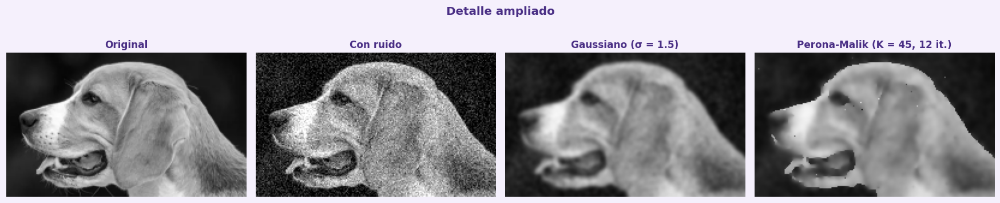

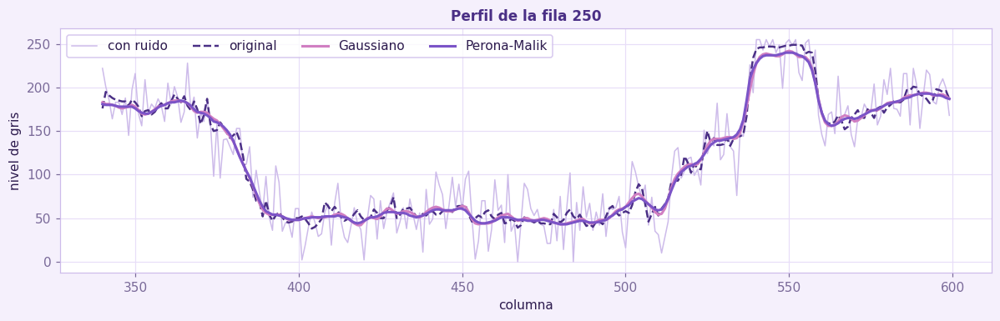

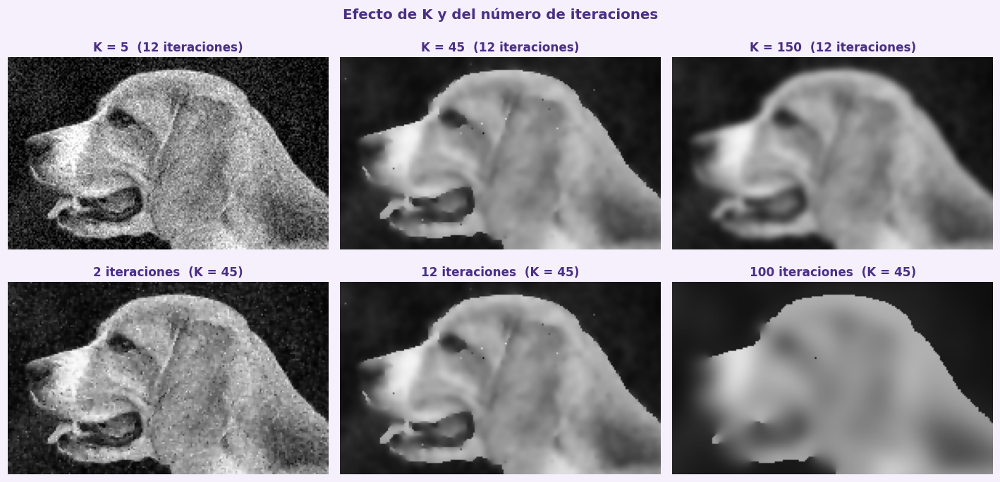

In [22]:
gris5 = cv.resize(leer_imagen('imagen5.png', cv.IMREAD_GRAYSCALE), (800, 528), interpolation=cv.INTER_AREA)
ruidosa5 = np.clip(gris5 + np.random.default_rng(1).normal(0, 25, gris5.shape), 0, 255).astype(np.uint8)

def mejor_psnr(candidatos):
    clave = max(candidatos, key=lambda k: cv.PSNR(gris5, candidatos[k]))
    return clave, candidatos[clave]

(sig_g,), gauss5 = mejor_psnr({(s,): cv.GaussianBlur(ruidosa5, (0, 0), s) for s in (0.6, 0.8, 1.0, 1.2, 1.5, 1.8, 2.2, 2.6, 3.0, 3.5)})
(sc_b, ss_b), bilat5 = mejor_psnr({(sc, ss): cv.bilateralFilter(ruidosa5, 9, sc, ss) for sc in (20, 30, 40, 60, 80) for ss in (2, 3, 5, 9)})
(K_pm, it_pm), pm5 = mejor_psnr({(K, it): perona_malik(ruidosa5, it, K) for K in (10, 15, 20, 30, 45, 60) for it in (3, 5, 8, 12, 20, 40)})

print(f"{'Método':<36}{'PSNR (dB)':>10}{'SSIM':>8}")
for etiqueta, im in [('Con ruido (σ = 25)', ruidosa5), (f'Gaussiano (σ = {sig_g})', gauss5),
                     (f'Bilateral (σc = {sc_b}, σs = {ss_b})', bilat5), (f'Perona-Malik (K = {K_pm}, {it_pm} it.)', pm5)]:
    print(f'{etiqueta:<36}{cv.PSNR(gris5, im):>10.2f}{ssim(gris5, im):>8.3f}')

y0, x0, alto, ancho = 85, 140, 120, 200
def recorte(im): return im[y0:y0 + alto, x0:x0 + ancho]
mostrar([recorte(gris5), recorte(ruidosa5), recorte(gauss5), recorte(pm5)],
        ['Original', 'Con ruido', f'Gaussiano (σ = {sig_g})', f'Perona-Malik (K = {K_pm}, {it_pm} it.)'],
        columnas=4, figsize=(16, 3.6), suptitulo='Detalle ampliado')

fila, c0, c1 = 250, 340, 600
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(np.arange(c0, c1), ruidosa5[fila, c0:c1], color=LILA['suave'], lw=1, label='con ruido')
ax.plot(np.arange(c0, c1), gris5[fila, c0:c1], color=LILA['oscuro'], lw=1.6, ls='--', label='original')
ax.plot(np.arange(c0, c1), gauss5[fila, c0:c1], color='#D17FC2', lw=2, label='Gaussiano')
ax.plot(np.arange(c0, c1), pm5[fila, c0:c1], color=LILA['primario'], lw=2, label='Perona-Malik')
ax.set_title(f'Perfil de la fila {fila}')
ax.set_xlabel('columna'); ax.set_ylabel('nivel de gris'); ax.grid(True); ax.legend(ncol=4)
fig.tight_layout(); plt.show()

mostrar([recorte(perona_malik(ruidosa5, it_pm, K)) for K in (5, K_pm, 150)] +
        [recorte(perona_malik(ruidosa5, it, K_pm)) for it in (2, it_pm, 100)],
        [f'K = {K}  ({it_pm} iteraciones)' for K in (5, K_pm, 150)] +
        [f'{it} iteraciones  (K = {K_pm})' for it in (2, it_pm, 100)],
        columnas=3, figsize=(13, 6.6), suptitulo='Efecto de K y del número de iteraciones')


**Qué vemos.** Con ruido gaussiano de σ = 25, y buscando para cada método los mejores parámetros con la imagen limpia como referencia:

- En PSNR, Perona-Malik (31.46 dB) y el bilateral (31.47 dB) empatan, y los dos superan al Gaussiano (30.70 dB). En SSIM, Perona-Malik sale mejor (0.853, frente a 0.824 del bilateral y 0.813 del Gaussiano).
- En el detalle ampliado, el contorno de la cabeza se mantiene nítido con Perona-Malik y se difumina con el Gaussiano. En el perfil de la fila los dos filtros se parecen bastante, así que la ventaja está sobre todo en los contornos.
- **Inconvenientes.** La imagen queda "a trozos", con zonas planas de bordes duros, y se pierde textura fina (pelo, bigotes). Con 100 iteraciones se destruye el detalle.
- **Efecto de los parámetros.** Con $K$ muy pequeño casi todo se considera borde y casi no se filtra. Con $K$ muy grande todo difunde y se comporta como un Gaussiano. Más iteraciones suavizan más.


## Parte B · Dos filtros de nuestra invención

Son propuestas nuestras, que hemos programado y medido. Se parecen a ideas conocidas (filtros medianos con decisión previa, gradientes robustos), así que no afirmamos que sean nuevos: lo que sí hacemos es comprobar con datos en qué situaciones funcionan mejor que los filtros de clase y en cuáles no.

### Filtro 1 · Mediana selectiva de vecinos válidos (quitar ruido)

**Problema que resuelve.** El filtro mediano de clase cambia **todos** los píxeles, incluidos los que estaban bien, y con ruido denso la mediana de la ventana incluye también valores corrompidos. En el ruido de sal y pimienta se sabe qué valores son sospechosos: los que valen exactamente 0 o 255.

**Algoritmo (por canal).**
1. Marcar como *dudosos* los píxeles con valor 0 o 255. Los demás **no se tocan**.
2. Para cada píxel dudoso, tomar la ventana 3×3 y calcular la **mediana solo de los vecinos que no son dudosos**.
3. Si en la ventana hay menos de 3 vecinos válidos, ampliar la ventana (5×5, 7×7, ... hasta 11×11) hasta que los haya.
4. Si aún así no hay suficientes, usar la mediana normal 3×3 como último recurso.

**Limitaciones.** Supone que el ruido son exactamente los valores 0 y 255: no sirve para ruido gaussiano. Un píxel legítimo que valga 0 o 255 (negro o blanco saturado) también se sustituye por la mediana de sus vecinos.


Densidad (cada valor)   Método                     PSNR (dB)    SSIM
2 % a 0 y 2 % a 255     sin filtrar                    18.36   0.543
                        Mediana 3×3                    25.04   0.782
                        Mediana 3×3, 2 pasadas         24.44   0.752
                        Mediana selectiva              37.58   0.987
5 % a 0 y 5 % a 255     sin filtrar                    14.44   0.308
                        Mediana 3×3                    24.65   0.772
                        Mediana 3×3, 2 pasadas         24.24   0.747
                        Mediana selectiva              33.58   0.973
15 % a 0 y 15 % a 255   sin filtrar                     9.68   0.112
                        Mediana 3×3                    20.56   0.629
                        Mediana 3×3, 2 pasadas         23.03   0.713
                        Mediana selectiva              28.30   0.919

Tiempo sobre imagen6.png: 0.37 s


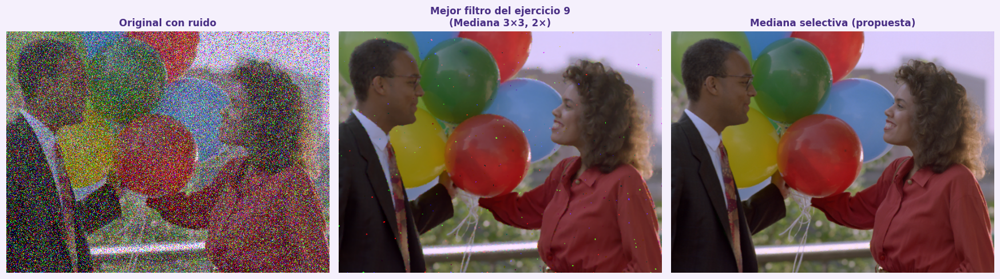

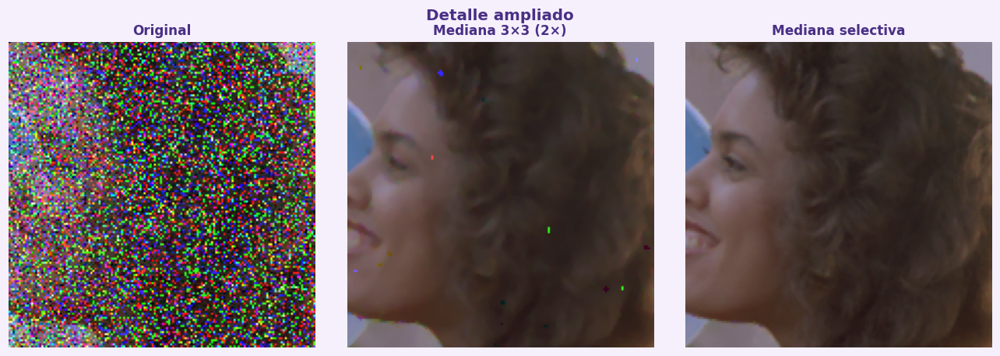

In [23]:
from numpy.lib.stride_tricks import sliding_window_view
import warnings, time

def mediana_selectiva(imagen, ventanas=(3, 5, 7, 9, 11), min_validos=3):
    """Cambia solo los valores 0 o 255 por la mediana de los vecinos que no valen 0 ni 255.
    Si hay menos de `min_validos` vecinos válidos, prueba con la ventana siguiente."""
    salida = imagen.copy()
    es_gris = imagen.ndim == 2
    for c in range(1 if es_gris else imagen.shape[2]):
        canal = imagen if es_gris else imagen[..., c]
        dudoso = (canal == 0) | (canal == 255)
        valido = np.where(dudoso, np.nan, canal.astype(np.float32))
        resultado, pendiente = canal.copy(), dudoso.copy()
        for k in ventanas:
            if not pendiente.any():
                break
            r = k // 2
            ventana = sliding_window_view(np.pad(valido, r, mode='reflect'), (k, k))[pendiente].reshape(-1, k * k)
            suficientes = np.isfinite(ventana).sum(axis=1) >= min_validos
            with warnings.catch_warnings():
                warnings.simplefilter('ignore', RuntimeWarning)
                mediana = np.nanmedian(ventana[suficientes], axis=1)
            posiciones = np.argwhere(pendiente)[suficientes]
            resultado[posiciones[:, 0], posiciones[:, 1]] = np.rint(mediana).astype(np.uint8)
            pendiente[posiciones[:, 0], posiciones[:, 1]] = False
        if pendiente.any():
            resultado[pendiente] = cv.medianBlur(canal, 3)[pendiente]
        if es_gris:
            salida = resultado
        else:
            salida[..., c] = resultado
    return salida

metodos = {
    'Mediana 3×3':         lambda x: cv.medianBlur(x, 3),
    'Mediana 3×3, 2 pasadas': lambda x: cv.medianBlur(cv.medianBlur(x, 3), 3),
    'Mediana selectiva':   mediana_selectiva,
}
print(f"{'Densidad (cada valor)':<24}{'Método':<26}{'PSNR (dB)':>10}{'SSIM':>8}")
for p in (0.02, 0.05, 0.15):
    con_ruido = ruido_sal_pimienta(limpia, p)
    print(f"{f'{100 * p:.0f} % a 0 y {100 * p:.0f} % a 255':<24}{'sin filtrar':<26}{cv.PSNR(limpia, con_ruido):>10.2f}{ssim(limpia, con_ruido):>8.3f}")
    for nombre, f in metodos.items():
        out = f(con_ruido)
        print(f"{'':<24}{nombre:<26}{cv.PSNR(limpia, out):>10.2f}{ssim(limpia, out):>8.3f}")

t = time.time(); propio6 = mediana_selectiva(imagen6); print(f'\nTiempo sobre imagen6.png: {time.time() - t:.2f} s')

y0, x0, lado = 90, 430, 150
mostrar([imagen6, imagen6_salida, propio6],
        ['Original con ruido', f'Mejor filtro del ejercicio 9\n({nombre_mejor}, {pasadas_mejor}×)', 'Mediana selectiva (propuesta)'],
        columnas=3, figsize=(16, 4.4))
mostrar([r[y0:y0 + lado, x0:x0 + lado] for r in (imagen6, imagen6_salida, propio6)],
        ['Original', f'{nombre_mejor} ({pasadas_mejor}×)', 'Mediana selectiva'], columnas=3, figsize=(12, 4.2),
        suptitulo='Detalle ampliado')


**Resultados.** Comparado con el filtro mediano de clase sobre la foto con ruido sintético:

| Densidad (cada valor) | Mejor mediana 3×3 de clase | Mediana selectiva |
|---|---|---|
| 2 % a 0 y 2 % a 255 | 25.0 dB, SSIM 0.78 | **37.6 dB, SSIM 0.99** |
| 5 % a 0 y 5 % a 255 | 24.7 dB, SSIM 0.77 | **33.6 dB, SSIM 0.97** |
| 15 % a 0 y 15 % a 255 | 23.0 dB, SSIM 0.71 (2 pasadas) | **28.3 dB, SSIM 0.92** |

Sobre `imagen6.png` desaparecen los puntos sueltos que sí quedan con la mediana, y los píxeles que no estaban corrompidos no se modifican, por lo que se conserva mejor el detalle. Tarda menos de un segundo. La ventaja depende de saber que el ruido son exactamente los valores 0 y 255, que es lo que medimos en el ejercicio 9.


### Filtro 2 · Gradiente mediano de 5 filas (detectar bordes)

**Problema que resuelve.** Sobel calcula la derivada horizontal como una **suma ponderada** de las diferencias $I(x+1, y+k) - I(x-1, y+k)$ de 3 filas. Si hay un píxel corrupto en esa ventana, su error entra entero en la suma y aparece un falso borde. Nuestra propuesta sustituye la suma por la **mediana**, que ignora los valores atípicos.

**Definición.** Con $r = 2$ (5 filas y 5 columnas):

$$G_x(x, y) = \operatorname*{mediana}_{k=-2,\dots,2}\big[\, I(x+1,\, y+k) - I(x-1,\, y+k) \,\big], \qquad G_y(x, y) = \operatorname*{mediana}_{k=-2,\dots,2}\big[\, I(x+k,\, y+1) - I(x+k,\, y-1) \,\big]$$

y la intensidad del borde es $\sqrt{G_x^2 + G_y^2}$. Un borde real afecta a las 5 diferencias, y un píxel corrupto afecta como mucho a unas pocas, así que la mediana se queda con el valor del borde. Es no lineal y no necesita suavizar la imagen antes.

**Cómo lo evaluamos.** Tomamos como referencia los bordes de Canny de la imagen limpia. A cada detector le pedimos tantos píxeles de borde como tiene la referencia (los de mayor respuesta) y calculamos el F1, aceptando un píxel de error de posición. Así no hay que elegir un umbral distinto para cada nivel de ruido.


Condición               F1 Sobel    F1 gradiente mediano
Sin ruido                  0.767                   0.747
Sal y pimienta 1 %         0.302                   0.742
Sal y pimienta 3 %         0.247                   0.718
Sal y pimienta 6 %         0.246                   0.614
Gaussiano σ = 15           0.787                   0.769


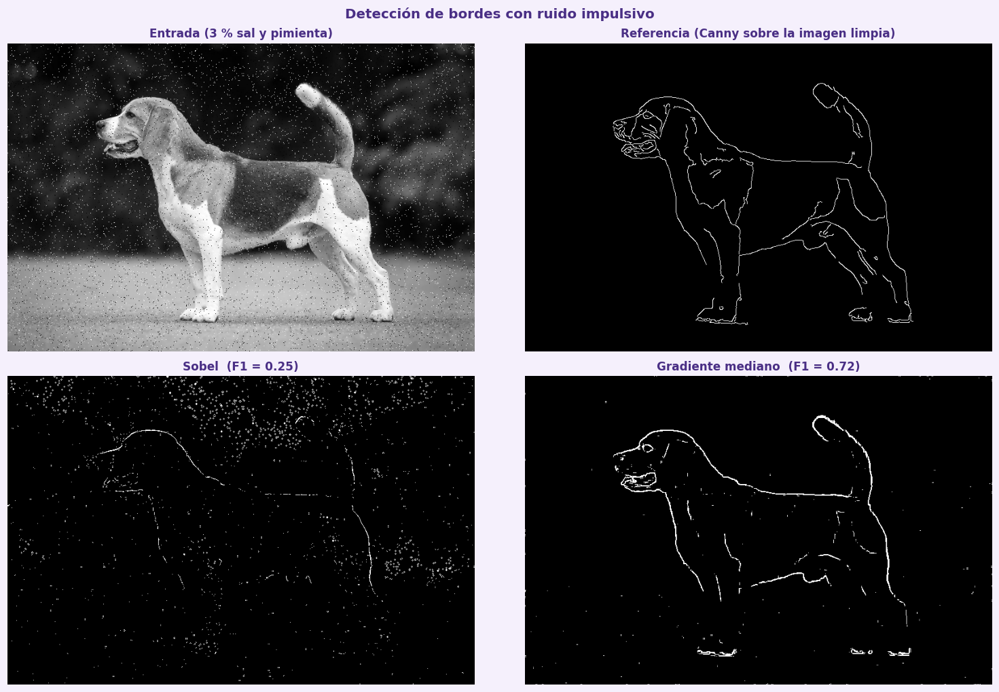

In [ ]:
def gradiente_mediano(gris, filas=5):
    """|G| con Gx = mediana de las `filas` diferencias horizontales I(x+1,y+k) - I(x-1,y+k) (y análogo para Gy)."""
    x = gris.astype(np.float32)
    H, W = x.shape
    r = filas // 2
    p = np.pad(x, r + 1, mode='edge')
    dx = p[:, 2:] - p[:, :-2]
    dy = p[2:, :] - p[:-2, :]
    gx = np.median(np.stack([dx[r + 1 + k:r + 1 + k + H, r:r + W] for k in range(-r, r + 1)]), axis=0)
    gy = np.median(np.stack([dy[r:r + H, r + 1 + k:r + 1 + k + W] for k in range(-r, r + 1)]), axis=0)
    return np.hypot(gx, gy)

def norma_sobel(gris):
    x = gris.astype(np.float32)
    return np.hypot(cv.Sobel(x, cv.CV_32F, 1, 0), cv.Sobel(x, cv.CV_32F, 0, 1))

def bordes_top_k(respuesta, k):
    """Los k píxeles con mayor respuesta."""
    return respuesta >= np.partition(respuesta.ravel(), -k)[-k]

def f1_bordes(borde, referencia):
    """F1 aceptando un píxel de error de posición."""
    cerca = lambda m: cv.dilate(m.astype(np.uint8), np.ones((3, 3), np.uint8)) > 0
    precision = (borde & cerca(referencia)).sum() / borde.sum()
    recall = (referencia & cerca(borde)).sum() / referencia.sum()
    return 2 * precision * recall / (precision + recall)

g5 = cv.resize(leer_imagen('imagen5.png', cv.IMREAD_GRAYSCALE), (800, 528), interpolation=cv.INTER_AREA)
referencia = cv.Canny(cv.GaussianBlur(g5, (0, 0), 1.2), 60, 150) > 0
K_REF = int(referencia.sum())

def con_sal_pimienta(img, p, semilla):
    r = np.random.default_rng(semilla).random(img.shape)
    out = img.copy(); out[r < p / 2] = 0; out[r > 1 - p / 2] = 255
    return out

condiciones = [('Sin ruido', g5),
               ('Sal y pimienta 1 %', con_sal_pimienta(g5, 0.01, 1)),
               ('Sal y pimienta 3 %', con_sal_pimienta(g5, 0.03, 2)),
               ('Sal y pimienta 6 %', con_sal_pimienta(g5, 0.06, 3)),
               ('Gaussiano σ = 15',   np.clip(g5 + np.random.default_rng(4).normal(0, 15, g5.shape), 0, 255).astype(np.uint8))]
print(f"{'Condición':<22}{'F1 Sobel':>10}{'F1 gradiente mediano':>24}")
for etiqueta, im in condiciones:
    print(f'{etiqueta:<22}{f1_bordes(bordes_top_k(norma_sobel(im), K_REF), referencia):>10.3f}'
          f'{f1_bordes(bordes_top_k(gradiente_mediano(im), K_REF), referencia):>24.3f}')

ruido3 = condiciones[2][1]
b_sobel, b_med = bordes_top_k(norma_sobel(ruido3), K_REF), bordes_top_k(gradiente_mediano(ruido3), K_REF)
mostrar([ruido3, (referencia * 255).astype(np.uint8), (b_sobel * 255).astype(np.uint8), (b_med * 255).astype(np.uint8)],
        ['Entrada (3 % sal y pimienta)', 'Referencia (Canny sobre la imagen limpia)',
         f'Sobel  (F1 = {f1_bordes(b_sobel, referencia):.2f})', f'Gradiente mediano  (F1 = {f1_bordes(b_med, referencia):.2f})'],
        columnas=2, figsize=(14, 9.4), suptitulo='Detección de bordes con ruido impulsivo')


**Resultados.**

| Condición | F1 Sobel | F1 gradiente mediano |
|---|---|---|
| Sin ruido | 0.767 | 0.747 |
| Sal y pimienta 1 % | 0.302 | **0.742** |
| Sal y pimienta 3 % | 0.247 | **0.718** |
| Sal y pimienta 6 % | 0.246 | **0.614** |
| Gaussiano σ = 15 | 0.787 | 0.769 |

Con la imagen limpia o con ruido gaussiano es un poco peor que Sobel (unas dos centésimas de F1). Con ruido impulsivo la diferencia es grande: a Sobel le bastan un 1 % o un 3 % de píxeles corruptos para caer de 0.77 a 0.25-0.30, y el gradiente mediano mantiene 0.72-0.74 y aún 0.61 con un 6 %. Al ser no lineal no se puede expresar como una convolución (`cv.filter2D`) y hay que calcular medianas.


### Resumen del ejercicio 10

| | Qué hace | Mejor cuando | Peor cuando |
|---|---|---|---|
| **Perona-Malik** (técnica investigada) | Difusión que frena en los bordes | Ruido gaussiano | Ruido impulsivo; demasiadas iteraciones |
| **Mediana selectiva** (propuesta 1) | Cambia solo los 0 y 255 por la mediana de vecinos válidos | Sal y pimienta | Ruido gaussiano; imágenes con negros o blancos saturados legítimos |
| **Gradiente mediano** (propuesta 2) | Sobel con mediana en vez de suma | Bordes con ruido impulsivo | Imagen limpia o ruido gaussiano |


<div style="background:linear-gradient(90deg,#4A2F85,#A98BDB);padding:12px 22px;border-radius:14px"><h3 style="color:#FFFFFF;margin:0">Ficheros generados</h3></div>

In [25]:
import os
ficheros = ['vídeo2.mp4', 'video7.mp4', 'imagen3_ecualizada.png', 'video_otsu.mp4', 'imagen3_salida.png',
            'imagen5_salida.png', 'video4.mp4', 'imagen6_salida.png']
for f in ficheros:
    print(f"{'OK ' if os.path.isfile(f) else 'FALTA'}  {f:<26}" + (f'{os.path.getsize(f) / 1024:>10,.0f} KB' if os.path.isfile(f) else ''))


OK   vídeo2.mp4                     7,584 KB
OK   video7.mp4                     1,351 KB
OK   imagen3_ecualizada.png           150 KB
OK   video_otsu.mp4                15,407 KB
OK   imagen3_salida.png               150 KB
OK   imagen5_salida.png               180 KB
OK   video4.mp4                       560 KB
OK   imagen6_salida.png               354 KB
